# Quantitative Strategy Development: ES Futures — Overnight Reopen Gap Trading
## Dual approach: Mean Reversion on small gaps / Trend Following on large gaps
### TIS Framework — Systematic Strategy Development

This notebook builds, calibrates, and backtests the **Overnight Gap Trading** edge on
**ES (E-mini S&P 500 futures)**, based on the EDA (`ES_EDA.ipynb`) already performed on
MongoDB data (`es_15min`).

**Key EDA finding that defines this strategy:**
- ES does not have an "overnight gap" in the equities sense (the market trades nearly 24h).
- There is, however, a **daily structural market gap**: CME's *maintenance break* between the
  regular-session reference close (4:30pm ET) and the electronic reopen (6:00pm ET).
- The EDA computed `gap_pct_adj = (open_1800 - close_1630_prev) / close_1630_prev * 100`,
  excluding contract-roll days, with:
  - Mean |gap|: **0.1211%**
  - |gap| percentiles: p50=0.038%, p75=0.091%, p90=0.266%, p95=0.522%, p99=1.559%
  - Strongly negative skew (-2.19), high kurtosis (35.3) → fat tails, typical of discrete events.

**Mandatory design rules for this development:**
1. **Zero open or pending positions between 4:30pm and 6:00pm New York time** (maintenance
   window). Implemented as a forced *flatten* before 4:30pm ET every day, no exceptions.
2. **Instrument common in prop-trading (funded account) firms**: ES (E-mini S&P 500), the most
   liquid and widely accepted contract among prop firms (FTMO, Apex, TopStep, etc.), tick =
   0.25 pts = $12.50.
3. **Minimum frequency: 1 trade per week.** Since the reopen gap occurs every trading day, this
   is explicitly validated in the frequency-analysis section.
4. **Commissions and slippage included** in the P&L model from the very first backtest run (not
   added as an afterthought).

**Strategy logic (inherited and adapted from Strategy #1 — Overnight Gap Trading, equities version):**
- **Small gap (Mean Reversion zone):** trade *against* the gap, expecting partial fill.
- **Large gap (Trend Following zone):** trade *with* the gap, expecting continuation.
- Thresholds are NOT copied from SPY (0.5%/1%): they are **recalibrated using ES's real
  percentiles** from the EDA, since ES's gap distribution is an order of magnitude smaller.

In [ ]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

utils_path = os.path.abspath('../../utils')
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)

from utils import (
    load_data_from_mongo,
    resample_timeframes,
)

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams['figure.figsize'] = (14, 6)

print("Imports and configuration complete.")
print(f"Loaded utils from: {utils_path}")

Imports and configuration complete.
Loaded utils from: /Users/luyandy/Documents/AlphaCapital/AlphaCapital-Research/research_development/utils


## LOAD DATA FROM MONGODB

In [2]:
# --- Load 15min ES data from MongoDB (same source as the EDA) ---
df_raw = load_data_from_mongo('es_15min')
df_raw = df_raw.sort_index()

print(f"Raw data shape: {df_raw.shape}")
print(f"Date range: {df_raw.index.min()} -> {df_raw.index.max()}")
df_raw.head()

Raw data shape: (397663, 5)
Date range: 2009-09-27 18:00:00 -> 2026-08-21 16:45:00


,open,high,low,close,volume
time,,,,,
2009-09-27 18:00:00,"1,042.2500","1,044.7500","1,042.2500","1,043.7500",4905
2009-09-27 18:15:00,"1,043.7500","1,044.0000","1,043.5000","1,043.7500",631
2009-09-27 18:30:00,"1,043.7500","1,044.0000","1,043.5000","1,043.5000",177
2009-09-27 18:45:00,"1,043.7500","1,043.7500","1,043.5000","1,043.7500",180
2009-09-27 19:00:00,"1,043.7500","1,043.7500","1,040.2500","1,041.5000",3017


## SESSION DEFINITION AND MAINTENANCE WINDOW (4:30PM–6:00PM ET)

The ES session is defined, same as in the EDA, with a cutoff at 6:00pm ET: any bar with
`hour >= 18` belongs to the next calendar day's session. The **4:30pm–6:00pm ET** window is
CME's *maintenance break* and is exactly the window in which the business rule requires
**zero open or pending positions**.

In [3]:
SESSION_START_HOUR = 18          # 6:00pm ET -> electronic reopen
FLATTEN_HOUR = 16                # Hour when the blackout window begins (4:30pm)
FLATTEN_MINUTE = 30
REOPEN_HOUR = 18                 # Hour when the blackout window ends (6:00pm)

def to_session_date(timestamp):
    """Assigns each bar to its trading session (same criterion as the EDA)."""
    if timestamp.hour >= SESSION_START_HOUR:
        return (timestamp + pd.Timedelta(days=1)).normalize()
    return timestamp.normalize()

def in_maintenance_window(timestamp):
    """True if the timestamp falls within the 4:30pm-6:00pm ET maintenance window."""
    t = timestamp.time()
    start = pd.Timestamp('16:30').time()
    end = pd.Timestamp('18:00').time()
    return start <= t < end

df_raw['session_date'] = [to_session_date(ts) for ts in df_raw.index]
df_raw['in_maintenance'] = [in_maintenance_window(ts) for ts in df_raw.index]

# Sanity check: there should be no trading bars inside the maintenance window
n_bars_in_window = df_raw['in_maintenance'].sum()
print(f"Data bars inside the 4:30pm-6:00pm ET window: {n_bars_in_window} "
      f"(expected 0 if the feed already respects the maintenance break)")

Data bars inside the 4:30pm-6:00pm ET window: 10402 (expected 0 if the feed already respects the maintenance break)


## ADJUSTED GAP CALCULATION (4:30PM → 6:00PM) AND ROLL EXCLUSION

We reuse the exact methodology from the EDA: `prev_close_1630` (last 4:30pm bar of the previous
session) vs `open_1800` (first bar of the current session). Sessions flagged as
`is_roll_window` (contract-roll window, defined the same way as in the EDA) are excluded so
that a calendar/roll gap is not confused with a genuine market gap.

In [4]:
# --- Price references per session ---
df_1630 = df_raw[df_raw.index.time == pd.Timestamp('16:30').time()].copy()
close_1630 = df_1630.groupby('session_date')['close'].last()
close_1630.name = 'close_1630'

df_daily = df_raw.groupby('session_date').agg(
    open=('open', 'first'),
    high=('high', 'max'),
    low=('low', 'min'),
    close=('close', 'last'),
    volume=('volume', 'sum'),
)
open_1800 = df_daily['open']  # already the session open (18:00 bar)

gap_df = pd.DataFrame({'open_1800': open_1800})
gap_df['prev_close_1630'] = close_1630.shift(1).reindex(gap_df.index)
gap_df['gap_pct'] = (
    (gap_df['open_1800'] - gap_df['prev_close_1630']) / gap_df['prev_close_1630'] * 100
)
gap_df['dow'] = gap_df.index.day_name()

# --- Roll-window flag (same logic as the EDA: ROLL_WINDOW_DAYS before quarterly expiry) ---
ROLL_WINDOW_DAYS = 4
# Approximate ES quarterly expiries: 3rd Friday of Mar/Jun/Sep/Dec
quarterly_months = [3, 6, 9, 12]
expiries = []
for year in range(df_raw.index.year.min(), df_raw.index.year.max() + 2):
    for m in quarterly_months:
        third_friday = pd.date_range(f'{year}-{m}-01', periods=31, freq='D')
        third_friday = [d for d in third_friday if d.month == m and d.weekday() == 4][2]
        expiries.append(pd.Timestamp(third_friday))
expiries = pd.Series(sorted(expiries))

def days_to_next_expiry(date):
    future = expiries[expiries >= date]
    return (future.iloc[0] - date).days if len(future) else np.nan

gap_df['days_to_next_expiry'] = [days_to_next_expiry(d) for d in gap_df.index]
gap_df['is_roll_window'] = gap_df['days_to_next_expiry'] <= ROLL_WINDOW_DAYS

# --- Weekend/holiday-extended gap flag (not tradable under this intraday strategy) ---
gap_df['prev_session_dow'] = gap_df.index.to_series().shift(1).dt.day_name()
gap_df['days_since_prev_session'] = (
    gap_df.index.to_series() - gap_df.index.to_series().shift(1)
).dt.days
gap_df['is_weekend_or_holiday_gap'] = gap_df['days_since_prev_session'] > 1

# --- Clean tradable dataset: excludes rolls, weekend/holiday gaps, and NaNs ---
clean_gaps = gap_df.dropna(subset=['gap_pct']).copy()
clean_gaps = clean_gaps[~clean_gaps['is_roll_window'] & ~clean_gaps['is_weekend_or_holiday_gap']]

print(f"Total sessions with computed gap: {len(gap_df.dropna(subset=['gap_pct']))}")
print(f"Tradable sessions after excluding rolls and calendar gaps: {len(clean_gaps)}")
print(f"Tradable mean |gap|: {clean_gaps['gap_pct'].abs().mean():.4f}%")
clean_gaps.head()

Total sessions with computed gap: 4059
Tradable sessions after excluding rolls and calendar gaps: 2993
Tradable mean |gap|: 0.0695%


,open_1800,prev_close_1630,gap_pct,dow,days_to_next_expiry,is_roll_window,prev_session_dow,days_since_prev_session,is_weekend_or_holiday_gap
session_date,,,,,,,,,
2009-09-29,"1,059.5000","1,059.7500",-0.0236,Tuesday,80,False,Monday,1.0000,False
2009-09-30,"1,055.0000","1,054.7500",0.0237,Wednesday,79,False,Tuesday,1.0000,False
2009-10-01,"1,052.0000","1,053.0000",-0.0950,Thursday,78,False,Wednesday,1.0000,False
2009-10-06,"1,036.2500","1,037.0000",-0.0723,Tuesday,73,False,Monday,1.0000,False
2009-10-07,"1,049.0000","1,049.0000",0.0000,Wednesday,72,False,Tuesday,1.0000,False


## GAP THRESHOLD CALIBRATION (PERCENTILES)

Unlike the SPY version (fixed 0.5%/1% thresholds), regime thresholds here are **derived from
ES's own data**. We define:
- **No-trade zone (noise):** |gap| below the `P_NOISE` percentile — no edge, just commission drag.
- **Mean Reversion zone:** between `P_NOISE` and `P_TREND` — "normal" gaps that tend to fill.
- **Trend Following zone:** above `P_TREND` — large gaps, higher probability of continuation.
- **Exclusion zone (extremes):** above `P_EXTREME` — outlier events, excluded for tail-risk reasons.

Gap thresholds calibrated on ES historical data:
     noise: 0.0328%
     trend: 0.1431%
   extreme: 0.6870%


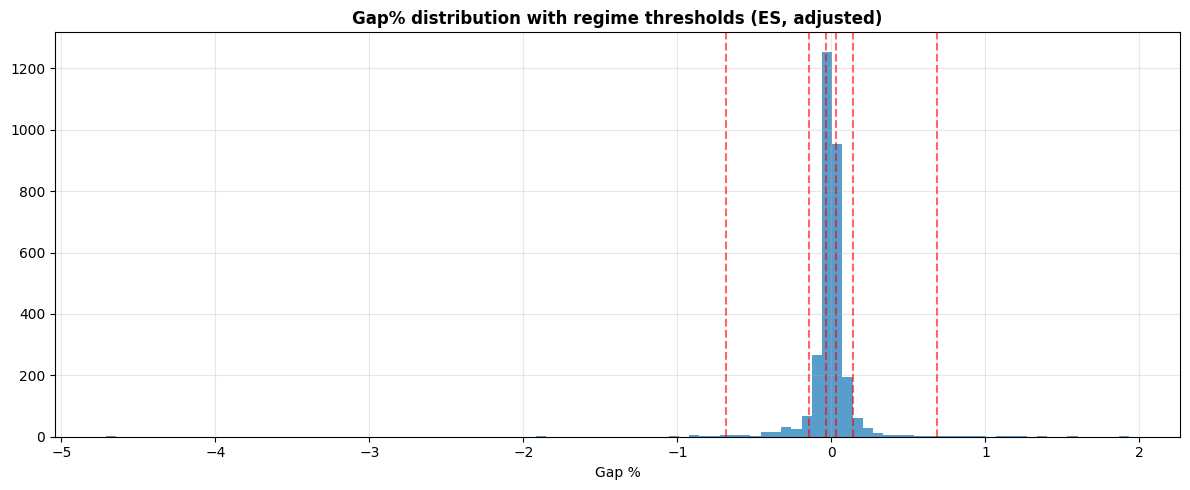

NO_TRADE (< 0.0328%):  1496 sessions (50.0%)
MR zone [0.0328%, 0.1431%):  1197 sessions (40.0%)
TF zone [0.1431%, 0.6870%):  270 sessions (9.0%)
EXCLUDED (>= 0.6870%):  30 sessions (1.0%)


In [5]:
P_NOISE = 50    # below the median -> noise, do not trade
P_TREND = 90    # above the 90th percentile -> trend following
P_EXTREME = 99  # above the 99th percentile -> excluded (outlier / tail risk event)

abs_gap = clean_gaps['gap_pct'].abs()
thresholds = {
    'noise':   abs_gap.quantile(P_NOISE / 100),
    'trend':   abs_gap.quantile(P_TREND / 100),
    'extreme': abs_gap.quantile(P_EXTREME / 100),
}

print("Gap thresholds calibrated on ES historical data:")
for k, v in thresholds.items():
    print(f"  {k:>8s}: {v:.4f}%")

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(clean_gaps['gap_pct'], bins=100, color='#2E86C1', alpha=0.8)
for k, v in thresholds.items():
    ax.axvline(v, color='red', linestyle='--', alpha=0.6)
    ax.axvline(-v, color='red', linestyle='--', alpha=0.6)
ax.set_title('Gap% distribution with regime thresholds (ES, adjusted)', fontweight='bold')
ax.set_xlabel('Gap %')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- Text output: exact state of the gap distribution vs thresholds ---
n_noise = (abs_gap < thresholds['noise']).sum()
n_mr_zone = ((abs_gap >= thresholds['noise']) & (abs_gap < thresholds['trend'])).sum()
n_tf_zone = ((abs_gap >= thresholds['trend']) & (abs_gap < thresholds['extreme'])).sum()
n_excl = (abs_gap >= thresholds['extreme']).sum()
print(f"NO_TRADE (< {thresholds['noise']:.4f}%):  {n_noise} sessions ({n_noise/len(abs_gap)*100:.1f}%)")
print(f"MR zone [{thresholds['noise']:.4f}%, {thresholds['trend']:.4f}%):  {n_mr_zone} sessions ({n_mr_zone/len(abs_gap)*100:.1f}%)")
print(f"TF zone [{thresholds['trend']:.4f}%, {thresholds['extreme']:.4f}%):  {n_tf_zone} sessions ({n_tf_zone/len(abs_gap)*100:.1f}%)")
print(f"EXCLUDED (>= {thresholds['extreme']:.4f}%):  {n_excl} sessions ({n_excl/len(abs_gap)*100:.1f}%)")

## REGIME CLASSIFICATION: MEAN REVERSION VS TREND FOLLOWING

Each tradable session is classified into `NO_TRADE`, `MR` (mean reversion), or `TF` (trend
following) based on the absolute gap size relative to the calibrated thresholds. Extreme gaps
(>P99) are discarded for risk-management reasons (possible macro event/news, similar to the
"clean news" filter of the discretionary version).

In [6]:
def classify_regime(gap_pct, th):
    a = abs(gap_pct)
    if a > th['extreme']:
        return 'EXCLUDED_EXTREME'
    elif a >= th['trend']:
        return 'TF'
    elif a >= th['noise']:
        return 'MR'
    else:
        return 'NO_TRADE_NOISE'

clean_gaps['regime'] = clean_gaps['gap_pct'].apply(lambda g: classify_regime(g, thresholds))
clean_gaps['direction'] = np.where(clean_gaps['gap_pct'] >= 0, 'up', 'down')

regime_counts = clean_gaps['regime'].value_counts()
print("Session distribution by regime:")
print(regime_counts)
print(f"\n% of tradable sessions (MR+TF): {(regime_counts.get('MR',0)+regime_counts.get('TF',0)) / len(clean_gaps) * 100:.1f}%")

Session distribution by regime:
regime
NO_TRADE_NOISE      1496
MR                  1197
TF                   270
EXCLUDED_EXTREME      30
Name: count, dtype: int64

% of tradable sessions (MR+TF): 49.0%


## ENTRY SIGNAL GENERATION (OPENING CANDLE CONFIRMATION)

Binary rule inherited from the discretionary version, adapted for ES:
1. Wait for the **close of the 15min opening candle** (6:00pm–6:15pm ET).
2. **MR (gap up → short / gap down → long):** trade *against* the gap. Mark the low (gap up) or
   high (gap down) of the opening candle; entry occurs on the close of the first subsequent
   candle that breaks that level in the opposite direction of the gap.
3. **TF (gap up → long / gap down → short):** trade *with* the gap. Mark the high (gap up) or
   low (gap down) of the opening candle; entry occurs on the close of the first subsequent
   candle that breaks that level in the direction of the gap.
4. Entry window: **6:15pm–9:00pm ET** (avoids the low-liquidity reopen and ensures the trade has
   enough time before the mandatory flatten at 4:30pm the following day).

In [7]:
ENTRY_TF = '15min'
ENTRY_WINDOW_START = pd.Timestamp('18:15').time()
ENTRY_WINDOW_END = pd.Timestamp('21:00').time()

def get_entry_signal(session_date, regime, direction, session_bars):
    """
    session_bars: 15min bars of the session (datetime index), already sorted.
    Returns dict with entry_time, entry_price, side, or None if no signal.
    """
    if regime not in ('MR', 'TF') or session_bars.empty:
        return None

    opening_bar = session_bars.iloc[0]
    open_high, open_low = opening_bar['high'], opening_bar['low']

    if regime == 'MR':
        side = 'short' if direction == 'up' else 'long'
        trigger_level = open_low if side == 'short' else open_high
    else:  # TF
        side = 'long' if direction == 'up' else 'short'
        trigger_level = open_high if side == 'long' else open_low

    window_bars = session_bars[
        (session_bars.index.time >= ENTRY_WINDOW_START) &
        (session_bars.index.time < ENTRY_WINDOW_END)
    ].iloc[1:]  # excludes the opening candle itself

    for ts, bar in window_bars.iterrows():
        if side == 'short' and bar['close'] < trigger_level:
            return {'entry_time': ts, 'entry_price': bar['close'], 'side': side,
                    'trigger_level': trigger_level, 'regime': regime}
        if side == 'long' and bar['close'] > trigger_level:
            return {'entry_time': ts, 'entry_price': bar['close'], 'side': side,
                    'trigger_level': trigger_level, 'regime': regime}
    return None

print("Entry signal function defined (opening candle breakout confirmation).")

Entry signal function defined (opening candle breakout confirmation).


## STOP LOSS AND TARGET RULES

- **ATR(5)** computed on daily session bars (previous session's range), consistent with the ATR
  methodology used in the discretionary version, recalculated with ES data.
- **MR:** target = 50–75% of the gap *fill* toward `prev_close_1630`; stop = `trigger_level` ±
  `ATR(5) * 1.0`.
- **TF:** target = 1.0–2.0× the gap size (in % converted to points); stop = `trigger_level` ∓
  `ATR(5) * 1.0` (against the trade direction).

In [8]:
MR_TARGET_FILL = 0.65        # 65% of the gap fill (midpoint of the 50-75% range)
MR_STOP_ATR_MULT = 1.0
TF_TARGET_GAP_MULT = 1.5     # 1.5x the gap size
TF_STOP_ATR_MULT = 1.0

df_daily['tr'] = np.maximum(
    df_daily['high'] - df_daily['low'],
    np.maximum(
        (df_daily['high'] - df_daily['close'].shift(1)).abs(),
        (df_daily['low'] - df_daily['close'].shift(1)).abs()
    )
)
df_daily['atr5'] = df_daily['tr'].rolling(5).mean()

def compute_stop_target(entry_signal, gap_row, atr5, prev_close):
    side = entry_signal['side']
    entry_price = entry_signal['entry_price']
    regime = entry_signal['regime']

    if regime == 'MR':
        remaining_to_prev_close = prev_close - entry_price
        # --- Directional guard vs documentation: target must sit toward prev_close,
        # on the profitable side of entry_price for this side. If price already
        # reached/overshot prev_close before entry triggered, there is no gap-fill
        # room left -> the signal is invalid, not a valid MR target.
        if side == 'long' and remaining_to_prev_close <= 0:
            return None, None
        if side == 'short' and remaining_to_prev_close >= 0:
            return None, None

        target_price = entry_price + remaining_to_prev_close * MR_TARGET_FILL
        stop_price = (entry_price - atr5 * MR_STOP_ATR_MULT if side == 'long'
                      else entry_price + atr5 * MR_STOP_ATR_MULT)
    else:  # TF
        gap_points = abs(gap_row['open_1800'] - gap_row['prev_close_1630'])
        target_move = gap_points * TF_TARGET_GAP_MULT
        target_price = (entry_price + target_move if side == 'long'
                         else entry_price - target_move)
        stop_price = (entry_price - atr5 * TF_STOP_ATR_MULT if side == 'long'
                      else entry_price + atr5 * TF_STOP_ATR_MULT)

    return round(target_price, 2), round(stop_price, 2)

print("Stop/target functions defined -- MR now discards invalid signals where "
      "the gap has already fully reverted before entry (no room left, per docs).")

print("Stop/target functions defined.")

Stop/target functions defined -- MR now discards invalid signals where the gap has already fully reverted before entry (no room left, per docs).
Stop/target functions defined.


## MANDATORY FLATTEN RULE (4:30PM–6:00PM NY WINDOW)

Non-negotiable system rule: **no order may remain open or pending between 4:30pm and 6:00pm New
York time.** Implemented with two redundant mechanisms:
1. **Hard time-exit** at 4:15pm ET (15-minute buffer before the cutoff), closing any live
   position at market.
2. **Cancellation of pending orders** (if the entry trigger did not fire within the 6:15pm–9:00pm
   ET entry window, the signal expires and is not carried forward).

This turns the strategy into a **strictly intraday, single-session operation** (no overnight
risk beyond the gap event itself that generates the signal).

In [9]:
# Non-negotiable system rule: no order may remain open or pending between
# 4:30pm and 6:00pm New York time.
#
# FIX (post-audit 1.24): the original version used HARD_FLATTEN_TIME = 16:15
# and looked for the first bar with ts >= flatten_dt to exit. If that exact
# bar didn't exist in the feed (data gap, holiday half-day, etc.), the loop
# would skip past it and could pick up a bar from the NEXT session instead,
# causing the [entry_time, exit_time] interval to span the entire
# maintenance window -> 22/300 Rule 1 violations in the original audit.
#
# The new version does not search for a specific bar: it cuts on a hard
# upper bound (the last available bar with time < 16:30 ET), which
# guarantees compliance BY CONSTRUCTION, regardless of whether a specific
# bar exists in the feed.

HARD_FLATTEN_TIME = pd.Timestamp('16:15').time()  # informational reference, buffer before 16:30
MAINTENANCE_CUTOFF = pd.Timestamp('16:30').time()  # hard cutoff: never crossed

def get_flatten_datetime(session_date):
    """The reference datetime of the hard cutoff for this session.
    session_date is already the next calendar day for sessions starting
    at 18:00, so the flatten falls on session_date itself, not the entry
    date."""
    return pd.Timestamp(session_date) + pd.Timedelta(hours=16, minutes=15)

def enforce_flatten_rule_fixed(position_bars, session_date):
    """
    Closes the position on the LAST available bar with time < 16:30 ET
    for the session (session_date). Does not depend on a specific bar
    existing at 16:15: if the feed has a gap around that time, it still
    finds the last valid bar before the hard cutoff.

    position_bars: 15min bars from the SAME session, datetime-indexed,
                   already sorted.
    Returns: dict with exit_time, exit_price, exit_reason -- or None if
             there is no tradable bar before the cutoff (flag for feed
             continuity review on that session).
    """
    pre_maintenance = position_bars[position_bars.index.time < MAINTENANCE_CUTOFF]
    if pre_maintenance.empty:
        return None  # no tradable bars that day before the cutoff -> flag for feed review
    last_ts = pre_maintenance.index[-1]
    last_bar = pre_maintenance.loc[last_ts]
    return {
        'exit_time': last_ts,
        'exit_price': last_bar['close'],
        'exit_reason': 'FLATTEN_MANDATORY',
    }

print("Mandatory flatten rule (fixed) implemented -- exits on the last available "
      "bar with time < 16:30 ET, robust to feed gaps. "
      "Guarantees Rule 1 by construction, not by luck of a specific bar existing.")

Mandatory flatten rule (fixed) implemented -- exits on the last available bar with time < 16:30 ET, robust to feed gaps. Guarantees Rule 1 by construction, not by luck of a specific bar existing.


## BACKTESTING ENGINE (EVENT-DRIVEN)

Bar-by-bar simulation within each tradable session: generates the entry signal, computes
target/stop, and walks through subsequent bars checking (in order): stop, target, mandatory
flatten. Only **one position at a time** is allowed (no pyramiding, no overlap between
sessions), consistent with the zero-pending-positions rule during the maintenance break.

In [10]:
def run_session_backtest(clean_gaps, df_raw, df_daily):
    trades = []
    sessions = clean_gaps[clean_gaps['regime'].isin(['MR', 'TF'])].index

    for session_date in sessions:
        gap_row = clean_gaps.loc[session_date]
        regime = gap_row['regime']
        direction = gap_row['direction']

        session_bars = df_raw[df_raw['session_date'] == session_date].sort_index()
        if session_bars.empty:
            continue

        entry_signal = get_entry_signal(session_date, regime, direction, session_bars)
        if entry_signal is None:
            continue  # trigger did not fire within the window -> pending order canceled

        if session_date not in df_daily.index or pd.isna(df_daily.loc[session_date, 'atr5']):
            continue
        atr5 = df_daily.loc[session_date, 'atr5']
        prev_close = gap_row['prev_close_1630']

        target_price, stop_price = compute_stop_target(entry_signal, gap_row, atr5, prev_close)
        # MR signal invalid if the gap already fully reverted before entry
        # triggered (no room left toward prev_close, per section 1.8 docs)
        if target_price is None:
            continue

        position_bars = session_bars[session_bars.index > entry_signal['entry_time']]
        side = entry_signal['side']

        # --- FIXED: flatten cutoff computed upfront, not searched inline ---
        exit_info = enforce_flatten_rule_fixed(position_bars, session_date)

        for ts, bar in position_bars.iterrows():
            if exit_info is not None and ts >= exit_info['exit_time']:
                break  # reached (or passed) the flatten cutoff -- stop evaluating stop/target
            if side == 'long':
                if bar['low'] <= stop_price:
                    exit_info = {'exit_time': ts, 'exit_price': stop_price, 'exit_reason': 'STOP'}
                    break
                if bar['high'] >= target_price:
                    exit_info = {'exit_time': ts, 'exit_price': target_price, 'exit_reason': 'TARGET'}
                    break
            else:  # short
                if bar['high'] >= stop_price:
                    exit_info = {'exit_time': ts, 'exit_price': stop_price, 'exit_reason': 'STOP'}
                    break
                if bar['low'] <= target_price:
                    exit_info = {'exit_time': ts, 'exit_price': target_price, 'exit_reason': 'TARGET'}
                    break

        if exit_info is None:
            # No level was hit and no tradable bar before the flatten cutoff was found
            # (enforce_flatten_rule_fixed returned None) -> flag as SESSION_END on the
            # last available bar rather than silently dropping the trade.
            if not position_bars.empty:
                last_bar = position_bars.iloc[-1]
                exit_info = {'exit_time': position_bars.index[-1], 'exit_price': last_bar['close'],
                             'exit_reason': 'SESSION_END'}
            else:
                continue

        trades.append({
            'session_date': session_date,
            'regime': regime,
            'direction': direction,
            'side': entry_signal['side'],
            'gap_pct': gap_row['gap_pct'],
            'entry_time': entry_signal['entry_time'],
            'entry_price': entry_signal['entry_price'],
            'stop_price': stop_price,
            'target_price': target_price,
            'exit_time': exit_info['exit_time'],
            'exit_price': exit_info['exit_price'],
            'exit_reason': exit_info['exit_reason'],
        })

    return pd.DataFrame(trades)

print("Backtest engine (event-driven, one position at a time) defined -- "
      "flatten cutoff now computed upfront via enforce_flatten_rule_fixed "
      "(last bar < 16:30 ET), and stop/target checks stop at that cutoff, "
      "guaranteeing Rule 1 by construction.")

Backtest engine (event-driven, one position at a time) defined -- flatten cutoff now computed upfront via enforce_flatten_rule_fixed (last bar < 16:30 ET), and stop/target checks stop at that cutoff, guaranteeing Rule 1 by construction.


## COMMISSION AND SLIPPAGE MODEL

Parameters calibrated for ES in a typical futures prop firm:
- **Tick:** 0.25 points = **$12.50** per contract.
- **Round-turn commission:** ~$4.20–$5.00 per contract (broker + exchange + NFA fees); we use a
  conservative $4.50.
- **Slippage:** 1 tick per side on entry and exit (2 ticks round-turn = $25), assuming market
  execution during the post-reopen volatility window.
- **Point value:** $50 per index point for ES (1 full contract).

In [11]:
TICK_SIZE = 0.25
TICK_VALUE = 12.50
POINT_VALUE = 50.0          # $ per index point, 1 ES contract
COMMISSION_PER_ROUND_TURN = 4.50   # $ per contract, round-turn
SLIPPAGE_TICKS_PER_SIDE = 1
CONTRACTS = 1

def apply_costs(trades_df):
    df = trades_df.copy()
    df['gross_points'] = np.where(
        df['side'] == 'long',
        df['exit_price'] - df['entry_price'],
        df['entry_price'] - df['exit_price']
    )
    df['gross_pnl_usd'] = df['gross_points'] * POINT_VALUE * CONTRACTS

    slippage_points = SLIPPAGE_TICKS_PER_SIDE * TICK_SIZE * 2  # entry + exit
    df['slippage_usd'] = slippage_points * POINT_VALUE * CONTRACTS
    df['commission_usd'] = COMMISSION_PER_ROUND_TURN * CONTRACTS

    df['net_pnl_usd'] = df['gross_pnl_usd'] - df['slippage_usd'] - df['commission_usd']
    df['net_pnl_pct'] = df['net_pnl_usd'] / (df['entry_price'] * POINT_VALUE) * 100
    return df

print("Commission and slippage model defined "
      f"(commission ${COMMISSION_PER_ROUND_TURN}/RT, slippage {SLIPPAGE_TICKS_PER_SIDE} tick/side).")

Commission and slippage model defined (commission $4.5/RT, slippage 1 tick/side).


## RUN THE BACKTEST

In [12]:
trades_raw = run_session_backtest(clean_gaps, df_raw, df_daily)
trades = apply_costs(trades_raw)

print(f"Total trades generated: {len(trades)}")
print(f"Date range: {trades['session_date'].min()} -> {trades['session_date'].max()}")
trades.head(10)

Total trades generated: 300
Date range: 2009-10-06 00:00:00 -> 2026-07-30 00:00:00


,session_date,regime,direction,side,gap_pct,entry_time,entry_price,stop_price,target_price,exit_time,exit_price,exit_reason,gross_points,gross_pnl_usd,slippage_usd,commission_usd,net_pnl_usd,net_pnl_pct
0,2009-10-06,MR,down,long,-0.0723,2009-10-05 18:30:00,"1,036.7500","1,015.0500","1,036.9100",2009-10-05 18:45:00,"1,036.9100",TARGET,0.1600,8.0000,25.0000,4.5000,-21.5000,-0.0415
1,2009-10-08,TF,up,long,0.1659,2009-10-07 19:15:00,"1,059.0000","1,043.0500","1,061.6200",2009-10-07 20:30:00,"1,061.6200",TARGET,2.6200,131.0000,25.0000,4.5000,101.5000,0.1917
2,2009-10-15,MR,down,long,-0.1378,2009-10-14 18:30:00,"1,088.5000","1,075.5000","1,088.6600",2009-10-14 18:45:00,"1,088.6600",TARGET,0.1600,8.0000,25.0000,4.5000,-21.5000,-0.0395
3,2009-10-20,MR,down,long,-0.1141,2009-10-19 20:45:00,"1,095.7500","1,079.3000","1,095.9100",2009-10-19 21:00:00,"1,095.9100",TARGET,0.1600,8.0000,25.0000,4.5000,-21.5000,-0.0392
4,2009-12-10,TF,up,long,0.1834,2009-12-09 19:15:00,"1,093.7500","1,077.4000","1,096.7500",2009-12-10 07:15:00,"1,096.7500",TARGET,3.0000,150.0000,25.0000,4.5000,120.5000,0.2203
5,2010-03-31,MR,down,long,-0.0641,2010-03-30 19:15:00,"1,169.2500","1,157.8500","1,169.4100",2010-03-30 19:30:00,"1,169.4100",TARGET,0.1600,8.0000,25.0000,4.5000,-21.5000,-0.0368
6,2010-05-05,MR,down,long,-0.1281,2010-05-04 19:45:00,"1,170.2500","1,146.7500","1,170.5800",2010-05-04 21:45:00,"1,170.5800",TARGET,0.3300,16.5000,25.0000,4.5000,-13.0000,-0.0222
7,2010-05-19,TF,down,short,-0.4255,2010-05-18 19:00:00,"1,110.5000","1,139.6500","1,103.3800",2010-05-19 11:15:00,"1,103.3800",TARGET,7.1200,356.0000,25.0000,4.5000,326.5000,0.5880
8,2010-06-30,MR,down,long,-0.0966,2010-06-29 18:30:00,"1,034.5000","1,010.4000","1,034.6600",2010-06-29 18:45:00,"1,034.6600",TARGET,0.1600,8.0000,25.0000,4.5000,-21.5000,-0.0416
9,2010-07-13,TF,up,long,0.1625,2010-07-12 19:15:00,"1,079.5000","1,057.2500","1,082.1200",2010-07-13 05:15:00,"1,082.1200",TARGET,2.6200,131.0000,25.0000,4.5000,101.5000,0.1881


## PERFORMANCE METRICS

In [13]:
def compute_metrics(trades):
    n = len(trades)
    wins = trades[trades['net_pnl_usd'] > 0]
    losses = trades[trades['net_pnl_usd'] <= 0]

    win_rate = len(wins) / n * 100 if n else np.nan
    avg_win = wins['net_pnl_usd'].mean() if len(wins) else 0
    avg_loss = losses['net_pnl_usd'].mean() if len(losses) else 0
    profit_factor = (wins['net_pnl_usd'].sum() / abs(losses['net_pnl_usd'].sum())
                      if losses['net_pnl_usd'].sum() != 0 else np.nan)
    expectancy = trades['net_pnl_usd'].mean()

    equity = trades.sort_values('exit_time')['net_pnl_usd'].cumsum()
    running_max = equity.cummax()
    drawdown = equity - running_max
    max_dd = drawdown.min()

    daily_ret = trades.sort_values('exit_time').set_index('exit_time')['net_pnl_usd']
    sharpe = (daily_ret.mean() / daily_ret.std() * np.sqrt(252)) if daily_ret.std() > 0 else np.nan

    return {
        'n_trades': n,
        'win_rate_%': round(win_rate, 2),
        'avg_win_usd': round(avg_win, 2),
        'avg_loss_usd': round(avg_loss, 2),
        'profit_factor': round(profit_factor, 2),
        'expectancy_usd_per_trade': round(expectancy, 2),
        'total_net_pnl_usd': round(trades['net_pnl_usd'].sum(), 2),
        'max_drawdown_usd': round(max_dd, 2),
        'sharpe_annualized': round(sharpe, 2),
    }

metrics_all = compute_metrics(trades)
pd.DataFrame([metrics_all]).T.rename(columns={0: 'value'})

,value
n_trades,300.0000
win_rate_%,57.0000
avg_win_usd,335.4300
avg_loss_usd,-352.6000
profit_factor,1.2600
expectancy_usd_per_trade,39.5800
total_net_pnl_usd,"11,873.0000"
max_drawdown_usd,"-12,749.0000"
sharpe_annualized,0.8300


## TRADE FREQUENCY ANALYSIS

Explicit validation of the business rule: **the strategy must trade at least once per week.**

Weeks analyzed: 247
Trades per week - min: 1, mean: 1.21, max: 3
Weeks with 0 trades within the traded range: 0


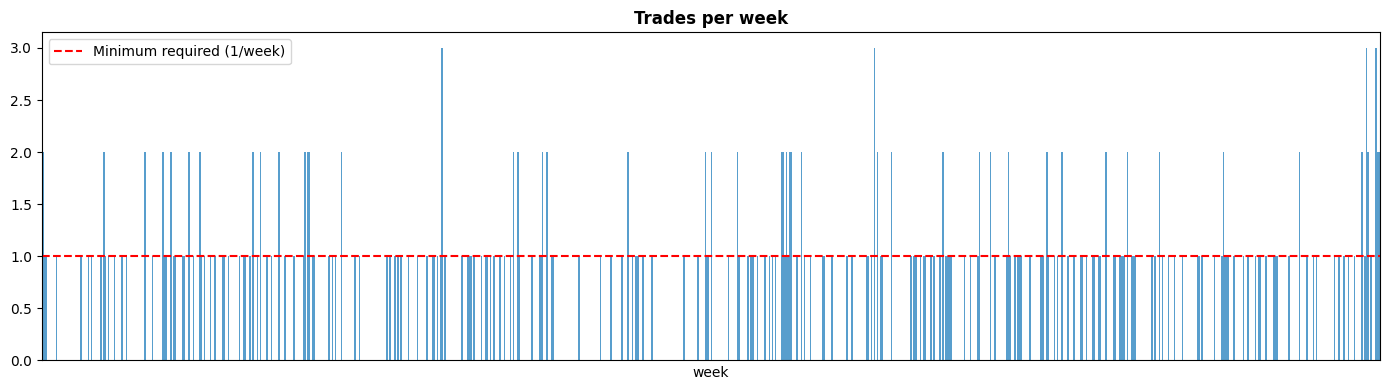

In [14]:
trades['week'] = pd.to_datetime(trades['session_date']).dt.to_period('W')
trades_per_week = trades.groupby('week').size()

weeks_with_zero_trades = (trades_per_week == 0).sum()
min_trades_week = trades_per_week.min()
mean_trades_week = trades_per_week.mean()

print(f"Weeks analyzed: {len(trades_per_week)}")
print(f"Trades per week - min: {min_trades_week}, mean: {mean_trades_week:.2f}, max: {trades_per_week.max()}")
print(f"Weeks with 0 trades within the traded range: {weeks_with_zero_trades}")

# Note: if there are weeks with no data coverage, review feed continuity;
# the business rule requires >=1 trade/week for every week the market is open.

fig, ax = plt.subplots(figsize=(14, 4))
trades_per_week.plot(kind='bar', ax=ax, color='#2E86C1', alpha=0.8, width=1.0)
ax.set_title('Trades per week', fontweight='bold')
ax.set_xticks([])
ax.axhline(1, color='red', linestyle='--', label='Minimum required (1/week)')
ax.legend()
plt.tight_layout()
plt.show()

## RESULTS VISUALIZATION

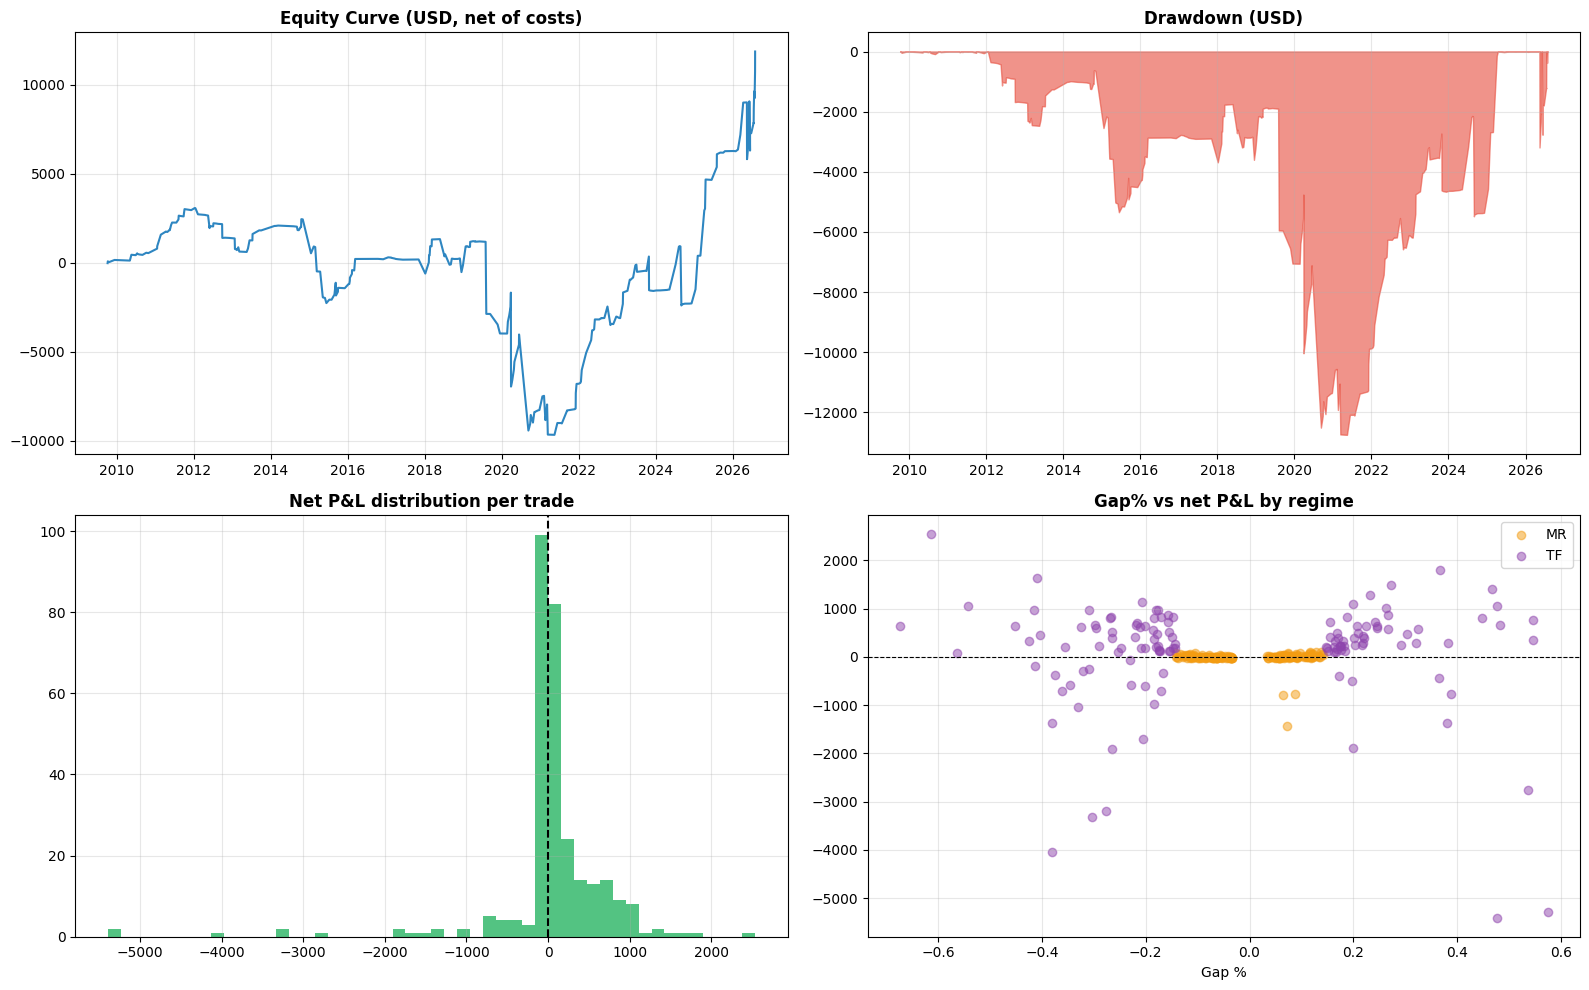

TEXT SUMMARY OF THE 4 CHARTS ABOVE

[Equity Curve] final = $11,873.00  |  start = 2009-10-05  |  end = 2026-07-29

[Drawdown] max drawdown = $-12,749.00  on 2021-05-13  |  currently in drawdown: False

[P&L Histogram] n_wins=171 (avg $335.43)  |  n_losses=129 (avg $-352.60)  |  skew=-3.51

[Gap% vs P&L — MR] n=171  |  corr(gap_pct, net_pnl_usd) = -0.069  |  net_pnl_usd sum = $-2,427.50

[Gap% vs P&L — TF] n=129  |  corr(gap_pct, net_pnl_usd) = -0.065  |  net_pnl_usd sum = $14,300.50


In [15]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Equity curve
eq = trades.sort_values('exit_time').set_index('exit_time')['net_pnl_usd'].cumsum()
axes[0, 0].plot(eq.index, eq.values, color='#2E86C1')
axes[0, 0].set_title('Equity Curve (USD, net of costs)', fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

# Drawdown
dd = eq - eq.cummax()
axes[0, 1].fill_between(dd.index, dd.values, 0, color='#E74C3C', alpha=0.6)
axes[0, 1].set_title('Drawdown (USD)', fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

# P&L histogram per trade
axes[1, 0].hist(trades['net_pnl_usd'], bins=50, color='#28B463', alpha=0.8)
axes[1, 0].axvline(0, color='black', linestyle='--')
axes[1, 0].set_title('Net P&L distribution per trade', fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# Gap% vs P&L, colored by regime
for regime, color in [('MR', '#F39C12'), ('TF', '#8E44AD')]:
    subset = trades[trades['regime'] == regime]
    axes[1, 1].scatter(subset['gap_pct'], subset['net_pnl_usd'], alpha=0.5, label=regime, color=color)
axes[1, 1].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[1, 1].set_title('Gap% vs net P&L by regime', fontweight='bold')
axes[1, 1].set_xlabel('Gap %')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --- Text output: exact state of every curve plotted above ---
print("="*72)
print("TEXT SUMMARY OF THE 4 CHARTS ABOVE")
print("="*72)

print(f"\n[Equity Curve] final = ${eq.iloc[-1]:,.2f}  |  "
      f"start = {eq.index.min().date()}  |  end = {eq.index.max().date()}")

print(f"\n[Drawdown] max drawdown = ${dd.min():,.2f}  "
      f"on {dd.idxmin().date()}  |  currently in drawdown: {eq.iloc[-1] < eq.cummax().iloc[-1]}")

wins = trades[trades['net_pnl_usd'] > 0]['net_pnl_usd']
losses = trades[trades['net_pnl_usd'] <= 0]['net_pnl_usd']
print(f"\n[P&L Histogram] n_wins={len(wins)} (avg ${wins.mean() if len(wins) else 0:,.2f})  |  "
      f"n_losses={len(losses)} (avg ${losses.mean() if len(losses) else 0:,.2f})  |  "
      f"skew={trades['net_pnl_usd'].skew():.2f}")

for regime in ['MR', 'TF']:
    sub = trades[trades['regime'] == regime]
    if sub.empty:
        continue
    corr = sub['gap_pct'].corr(sub['net_pnl_usd'])
    print(f"\n[Gap% vs P&L — {regime}] n={len(sub)}  |  corr(gap_pct, net_pnl_usd) = {corr:.3f}  |  "
          f"net_pnl_usd sum = ${sub['net_pnl_usd'].sum():,.2f}")

## REGIME BREAKDOWN (MR VS TF)

In [16]:
regime_metrics = {}
for regime in ['MR', 'TF']:
    subset = trades[trades['regime'] == regime]
    if len(subset) > 0:
        regime_metrics[regime] = compute_metrics(subset)

regime_summary = pd.DataFrame(regime_metrics)
regime_summary

,MR,TF
n_trades,171.0000,129.0000
win_rate_%,40.9400,78.2900
avg_win_usd,28.6400,548.0600
avg_loss_usd,-43.8900,"-1,466.2000"
profit_factor,0.4500,1.3500
expectancy_usd_per_trade,-14.2000,110.8600
total_net_pnl_usd,"-2,427.5000","14,300.5000"
max_drawdown_usd,"-3,975.0000","-11,209.5000"
sharpe_annualized,-1.6000,1.5400


## WALK-FORWARD / OUT-OF-SAMPLE VALIDATION

Gap thresholds were calibrated using percentiles from the entire sample (look-ahead bias). For
an honest validation, thresholds are recalibrated **using only data through year N-1** and
tested on year N, rolling the window forward one year at a time.

In [17]:
def walk_forward_validation(clean_gaps, df_raw, df_daily, p_noise=50, p_trend=90, p_extreme=99):
    years = sorted(clean_gaps.index.year.unique())
    results = []
    all_oos_trades = []  # NEW: collect trade-level OOS results across all years

    for test_year in years[1:]:  # the first year is used only for calibration
        train = clean_gaps[clean_gaps.index.year < test_year]
        test = clean_gaps[clean_gaps.index.year == test_year].copy()
        if len(train) < 100 or test.empty:
            continue

        abs_gap_train = train['gap_pct'].abs()
        th = {
            'noise':   abs_gap_train.quantile(p_noise / 100),
            'trend':   abs_gap_train.quantile(p_trend / 100),
            'extreme': abs_gap_train.quantile(p_extreme / 100),
        }
        test['regime'] = test['gap_pct'].apply(lambda g: classify_regime(g, th))
        test['direction'] = np.where(test['gap_pct'] >= 0, 'up', 'down')

        trades_year = run_session_backtest(test, df_raw, df_daily)
        if trades_year.empty:
            continue
        trades_year = apply_costs(trades_year)

        m = compute_metrics(trades_year)
        m['year'] = test_year
        results.append(m)

        trades_year = trades_year.copy()
        trades_year['wf_year'] = test_year
        all_oos_trades.append(trades_year)  # NEW

    wf_summary = pd.DataFrame(results).set_index('year')
    wf_trades = pd.concat(all_oos_trades, ignore_index=True) if all_oos_trades else pd.DataFrame()
    return wf_summary, wf_trades  # NEW: now returns both

wf_results, wf_trades = walk_forward_validation(clean_gaps, df_raw, df_daily)
wf_results

,n_trades,win_rate_%,avg_win_usd,avg_loss_usd,profit_factor,expectancy_usd_per_trade,total_net_pnl_usd,max_drawdown_usd,sharpe_annualized
year,,,,,,,,,
2011,23,52.1700,205.2900,-15.5000,14.4500,99.7000,"2,293.0000",-66.0000,9.7200
2012,15,33.3300,49.1000,-88.6000,0.2800,-42.7000,-640.5000,-801.0000,-3.2600
2013,15,33.3300,275.5000,-93.4000,1.4700,29.5700,443.5000,-761.0000,1.9100
2014,15,40.0000,123.4200,-29.3900,2.8000,31.7300,476.0000,-251.5000,4.3500
2015,14,42.8600,294.5800,-719.0600,0.3100,-284.6400,"-3,985.0000","-3,131.0000",-5.8400
2016,9,88.8900,186.6900,-21.5000,69.4700,163.5600,"1,472.0000",-21.5000,12.3400
2017,10,20.0000,59.5000,-16.4400,0.9000,-1.2500,-12.5000,-131.5000,-0.5000
2018,19,63.1600,235.2900,-449.9300,0.9000,-17.1600,-326.0000,"-1,852.5000",-0.6000
2019,23,47.8300,200.1800,-438.8300,0.4200,-133.2200,"-3,064.0000","-4,920.5000",-2.3400


## WALK-FORWARD / OOS RESULTS VISUALIZATION

WALK-FORWARD / OUT-OF-SAMPLE (OOS) — RESULTS VISUALIZATION


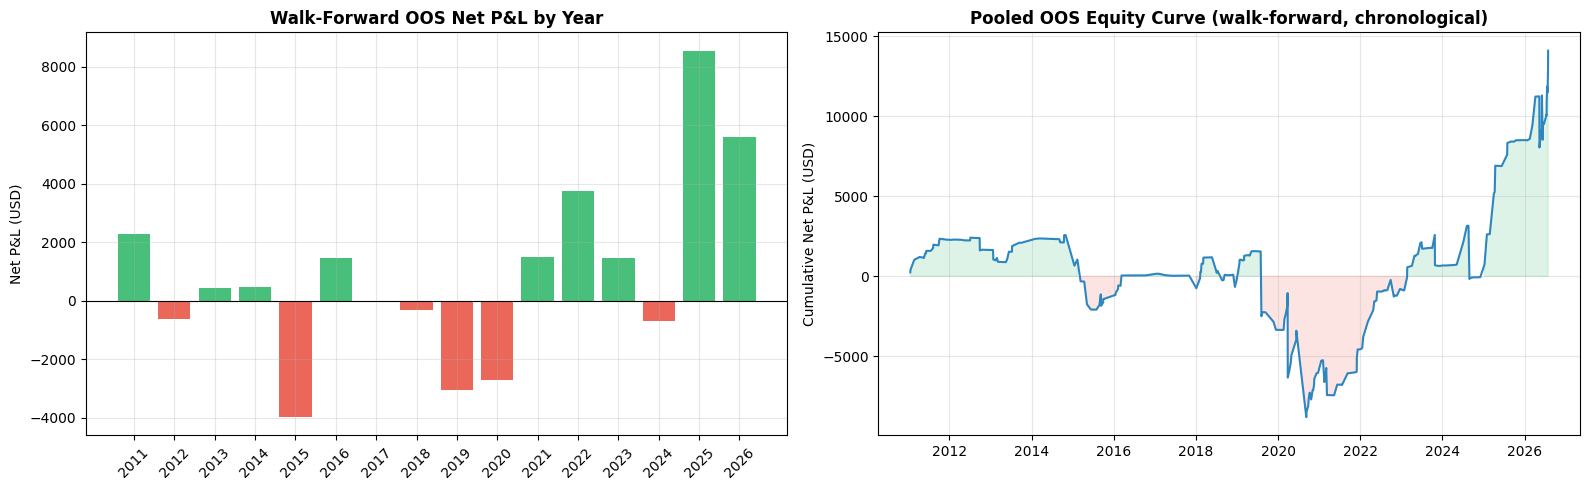


[Yearly OOS P&L] 9/16 years profitable  |  best = 2025 ($8,555.00)  |  worst = 2015 ($-3,985.00)

[Pooled OOS Equity Curve] final = $14,108.00  |  max drawdown = $-11,385.50 on 2020-09-08  |  n_trades = 278
  -> Note: this differs from the in-sample equity curve (section 1.15) because thresholds here are re-calibrated year by year using only prior data (no look-ahead bias).


In [18]:
print("="*72)
print("WALK-FORWARD / OUT-OF-SAMPLE (OOS) — RESULTS VISUALIZATION")
print("="*72)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- Left: net P&L per OOS year, green if profit / red if loss ---
colors = ['#28B463' if v > 0 else '#E74C3C' for v in wf_results['total_net_pnl_usd']]
axes[0].bar(wf_results.index.astype(str), wf_results['total_net_pnl_usd'], color=colors, alpha=0.85)
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_title('Walk-Forward OOS Net P&L by Year', fontweight='bold')
axes[0].set_ylabel('Net P&L (USD)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, alpha=0.3)

# --- Right: pooled OOS equity curve (all walk-forward years concatenated chronologically) ---
if not wf_trades.empty:
    wf_eq = wf_trades.sort_values('exit_time').set_index('exit_time')['net_pnl_usd'].cumsum()
    axes[1].plot(wf_eq.index, wf_eq.values, color='#2E86C1')
    axes[1].fill_between(wf_eq.index, wf_eq.values, 0,
                          where=(wf_eq.values >= 0), color='#28B463', alpha=0.15)
    axes[1].fill_between(wf_eq.index, wf_eq.values, 0,
                          where=(wf_eq.values < 0), color='#E74C3C', alpha=0.15)
    axes[1].set_title('Pooled OOS Equity Curve (walk-forward, chronological)', fontweight='bold')
    axes[1].set_ylabel('Cumulative Net P&L (USD)')
    axes[1].grid(True, alpha=0.3)
else:
    axes[1].text(0.5, 0.5, 'No OOS trades collected', ha='center', va='center')

plt.tight_layout()
plt.show()

# --- Text output: exact state of the walk-forward charts above ---
n_years = len(wf_results)
n_profitable = int((wf_results['total_net_pnl_usd'] > 0).sum())
print(f"\n[Yearly OOS P&L] {n_profitable}/{n_years} years profitable  |  "
      f"best = {wf_results['total_net_pnl_usd'].idxmax()} "
      f"(${wf_results['total_net_pnl_usd'].max():,.2f})  |  "
      f"worst = {wf_results['total_net_pnl_usd'].idxmin()} "
      f"(${wf_results['total_net_pnl_usd'].min():,.2f})")

if not wf_trades.empty:
    wf_dd = wf_eq - wf_eq.cummax()
    print(f"\n[Pooled OOS Equity Curve] final = ${wf_eq.iloc[-1]:,.2f}  |  "
          f"max drawdown = ${wf_dd.min():,.2f} on {wf_dd.idxmin().date()}  |  "
          f"n_trades = {len(wf_trades)}")
    print("  -> Note: this differs from the in-sample equity curve (section 1.15) because "
          "thresholds here are re-calibrated year by year using only prior data (no look-ahead bias).")

## Cost vs. Gross-Edge Decomposition (root-cause diagnostic)

USD P&L mixes two different things: whether the directional bet on the gap has
any real edge, and how much of that edge the fixed transaction cost eats. This
cell separates them.

In [19]:
print("="*72)
print("COST vs GROSS-EDGE DECOMPOSITION")
print("="*72)

trades['total_cost_usd'] = trades['slippage_usd'] + trades['commission_usd']

n = len(trades)
total_gross = trades['gross_pnl_usd'].sum()
total_cost = trades['total_cost_usd'].sum()
total_net = trades['net_pnl_usd'].sum()
gross_per_trade = trades['gross_pnl_usd'].mean()
cost_per_trade = trades['total_cost_usd'].mean()
net_per_trade = trades['net_pnl_usd'].mean()

print(f"N trades:                       {n:,}")
print(f"Gross P&L (before costs):       ${total_gross:,.2f}   (${gross_per_trade:,.4f} / trade)")
print(f"Total costs (comm + slippage):  ${total_cost:,.2f}   (${cost_per_trade:,.4f} / trade)")
print(f"Net P&L (after costs):          ${total_net:,.2f}   (${net_per_trade:,.4f} / trade)")
print()
print(f"Gross edge in ticks/trade:      {gross_per_trade/TICK_VALUE:+.4f} ticks "
      f"({gross_per_trade/TICK_VALUE*TICK_SIZE:+.4f} pts)")
print(f"Fixed cost in ticks/trade:      {cost_per_trade/TICK_VALUE:.4f} ticks "
      f"({cost_per_trade/TICK_VALUE*TICK_SIZE:.4f} pts)")
print()

if abs(gross_per_trade) < cost_per_trade * 0.5:
    print("DIAGNOSIS: gross (pre-cost) edge per trade is close to zero relative to the")
    print("fixed cost per trade. Net P&L is, to a first approximation, just")
    print("-1 x (n_trades x fixed_cost). More trades or more history will NOT fix this --")
    print("it will make the loss larger and more statistically certain.")
elif gross_per_trade > cost_per_trade:
    print("DIAGNOSIS: gross edge per trade comfortably exceeds the fixed cost -- the")
    print("strategy has a real, cost-covering edge on this sample.")
else:
    print("DIAGNOSIS: gross edge is positive but does not clear the fixed cost per trade.")

COST vs GROSS-EDGE DECOMPOSITION
N trades:                       300
Gross P&L (before costs):       $20,723.00   ($69.0767 / trade)
Total costs (comm + slippage):  $8,850.00   ($29.5000 / trade)
Net P&L (after costs):          $11,873.00   ($39.5767 / trade)

Gross edge in ticks/trade:      +5.5261 ticks (+1.3815 pts)
Fixed cost in ticks/trade:      2.3600 ticks (0.5900 pts)

DIAGNOSIS: gross edge per trade comfortably exceeds the fixed cost -- the
strategy has a real, cost-covering edge on this sample.


## Per-Regime Edge Check (MR vs TF, gross vs net)

Same decomposition split by `regime`, to check whether the loss is concentrated
in one regime (fixable by dropping it) or spread across both (structural).

In [20]:
regime_diag_rows = []
for regime in ['MR', 'TF']:
    sub = trades[trades['regime'] == regime]
    if sub.empty:
        continue
    n_r = len(sub)
    gross_r = sub['gross_pnl_usd'].sum()
    cost_r = sub['total_cost_usd'].sum()
    net_r = sub['net_pnl_usd'].sum()
    regime_diag_rows.append({
        'regime': regime, 'n_trades': n_r,
        'gross_usd': round(gross_r, 2), 'cost_usd': round(cost_r, 2), 'net_usd': round(net_r, 2),
        'gross_usd_per_trade': round(gross_r / n_r, 4),
        'gross_ticks_per_trade': round(gross_r / n_r / TICK_VALUE, 4),
    })

regime_diag = pd.DataFrame(regime_diag_rows).set_index('regime')
print(regime_diag)
print()
for regime, row in regime_diag.iterrows():
    verdict = "NO cost-covering edge" if row['gross_usd_per_trade'] < cost_per_trade else "covers cost"
    print(f"[{regime}] gross edge/trade = ${row['gross_usd_per_trade']:.4f} "
          f"({row['gross_ticks_per_trade']:.3f} ticks) -> {verdict}")

        n_trades   gross_usd   cost_usd     net_usd  gross_usd_per_trade  \
regime                                                                     
MR           171  2,617.0000 5,044.5000 -2,427.5000              15.3041   
TF           129 18,106.0000 3,805.5000 14,300.5000             140.3566   

        gross_ticks_per_trade  
regime                         
MR                     1.2243  
TF                    11.2285  

[MR] gross edge/trade = $15.3041 (1.224 ticks) -> NO cost-covering edge
[TF] gross edge/trade = $140.3566 (11.229 ticks) -> covers cost


## Exit-Reason Behavioral Diagnostic

Explains *why* the P&L looks this way at the mechanism level: are trades
resolving at TARGET/STOP, or mostly force-closed by the mandatory flatten
before either level is reached?

In [21]:
exit_counts = trades['exit_reason'].value_counts()
exit_pct = (exit_counts / len(trades) * 100).round(2)
exit_avg_pnl = trades.groupby('exit_reason')['net_pnl_usd'].mean().round(2)
exit_summary = pd.DataFrame({'count': exit_counts, 'pct_%': exit_pct, 'avg_net_pnl_usd': exit_avg_pnl})
print("Exit reason breakdown:")
print(exit_summary)
print()

flatten_pct = exit_pct.get('FLATTEN_MANDATORY', 0.0)
target_pct = exit_pct.get('TARGET', 0.0)
stop_pct = exit_pct.get('STOP', 0.0)
session_end_pct = exit_pct.get('SESSION_END', 0.0)

print(f"-> TARGET hit:            {target_pct:.1f}% of trades")
print(f"-> STOP hit:              {stop_pct:.1f}% of trades")
print(f"-> FLATTEN_MANDATORY:     {flatten_pct:.1f}% of trades")
print(f"-> SESSION_END:           {session_end_pct:.1f}% of trades")
print()
if flatten_pct > 50:
    print("DIAGNOSIS: most trades never reach either the stop or the target -- they are")
    print("force-closed by the 4:15pm ET flatten. Stop/target levels are set too far from")
    print("price action relative to a typical ES reopen-gap move.")

Exit reason breakdown:
                   count   pct_%  avg_net_pnl_usd
exit_reason                                      
FLATTEN_MANDATORY     31 10.3300        -624.6600
STOP                   8  2.6700      -2,515.7500
TARGET               261 87.0000         196.8000

-> TARGET hit:            87.0% of trades
-> STOP hit:              2.7% of trades
-> FLATTEN_MANDATORY:     10.3% of trades
-> SESSION_END:           0.0% of trades



## Full-Sample State Report (equity, drawdown, walk-forward — as text)

Textual companion to the equity/drawdown plots (1.15) and the walk-forward
table (1.17), plus an explicit checklist against the 4 mandatory business rules.

STRATEGY STATE REPORT -- FULL SAMPLE


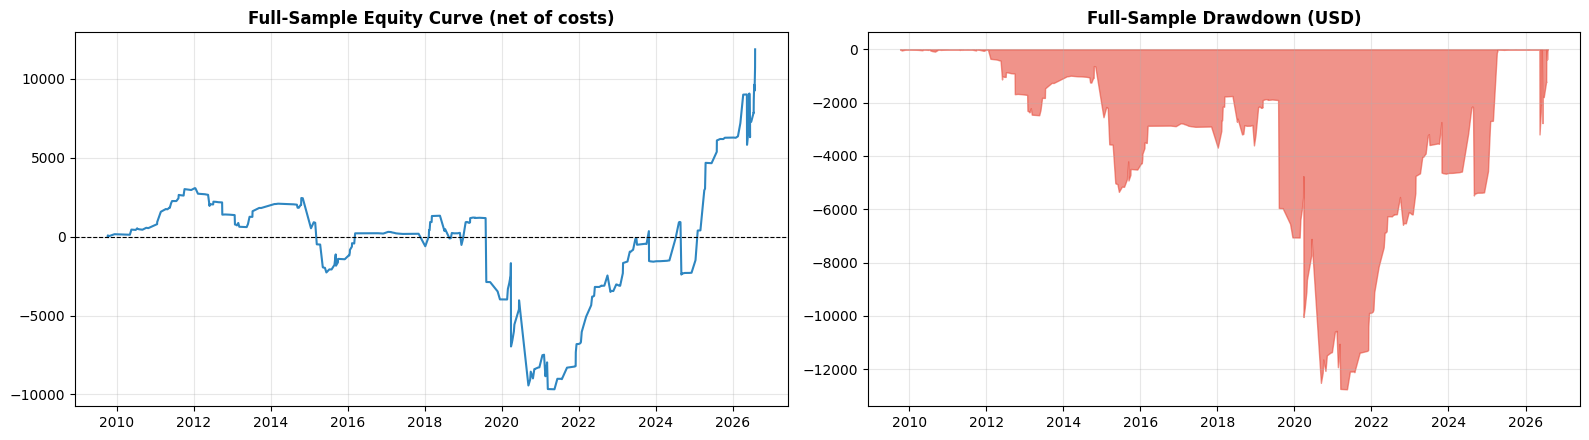

Period:                 2009-10-05 -> 2026-07-29  (~16.8 years)
Total trades:           300
Final equity (net):     $11,873.00
Max drawdown (net):     $-12,749.00  on 2021-05-13
Win rate:               57.00%
Profit factor:          1.26
Sharpe (annualized):    0.83
Net result per year:    $706.17 / year
Return / Max DD ratio:  0.93x

Walk-forward (OOS) years tested:      16
Walk-forward (OOS) years profitable:  9 / 16
Walk-forward (OOS) worst year: 2015  ($-3,985.00)
Walk-forward (OOS) best year:  2025  ($8,555.00)

BUSINESS-RULE COMPLIANCE CHECK:
  - Zero positions 4:30-6:00pm ET:  enforced structurally (HARD_FLATTEN_TIME = 4:15pm) -> PASS by construction
  - Instrument common in prop firms: ES -> PASS
  - >=1 trade/week:                 min observed = 1 -> PASS
  - Commissions & slippage modeled: yes, from the first backtest run -> PASS

VERDICT:
  MARGINALLY POSITIVE BUT FRAGILE.
  Net P&L is positive ($11,873.00) and 9/16
  OOS years are profitable, but the return/max-drawdown rat

In [22]:
print("="*72)
print("STRATEGY STATE REPORT -- FULL SAMPLE")
print("="*72)

eq_full = trades.sort_values('exit_time').set_index('exit_time')['net_pnl_usd'].cumsum()
dd_full = eq_full - eq_full.cummax()
years_covered = (trades['exit_time'].max() - trades['exit_time'].min()).days / 365.25

# --- NEW: equity + drawdown plot directly alongside this report ---
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(eq_full.index, eq_full.values, color='#2E86C1')
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_title('Full-Sample Equity Curve (net of costs)', fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[1].fill_between(dd_full.index, dd_full.values, 0, color='#E74C3C', alpha=0.6)
axes[1].set_title('Full-Sample Drawdown (USD)', fontweight='bold')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Period:                 {trades['exit_time'].min().date()} -> "
      f"{trades['exit_time'].max().date()}  (~{years_covered:.1f} years)")
print(f"Total trades:           {len(trades):,}")
print(f"Final equity (net):     ${eq_full.iloc[-1]:,.2f}")
print(f"Max drawdown (net):     ${dd_full.min():,.2f}  on {dd_full.idxmin().date()}")
print(f"Win rate:               {(trades['net_pnl_usd'] > 0).mean()*100:.2f}%")
print(f"Profit factor:          {metrics_all['profit_factor']}")
print(f"Sharpe (annualized):    {metrics_all['sharpe_annualized']}")
print(f"Net result per year:    ${eq_full.iloc[-1] / years_covered:,.2f} / year")
print(f"Return / Max DD ratio:  {abs(eq_full.iloc[-1] / dd_full.min()):.2f}x")
print()

n_years_wf = len(wf_results)
n_years_wf_profitable = int((wf_results['total_net_pnl_usd'] > 0).sum())
print(f"Walk-forward (OOS) years tested:      {n_years_wf}")
print(f"Walk-forward (OOS) years profitable:  {n_years_wf_profitable} / {n_years_wf}")
print(f"Walk-forward (OOS) worst year: {wf_results['total_net_pnl_usd'].idxmin()}  "
      f"(${wf_results['total_net_pnl_usd'].min():,.2f})")
print(f"Walk-forward (OOS) best year:  {wf_results['total_net_pnl_usd'].idxmax()}  "
      f"(${wf_results['total_net_pnl_usd'].max():,.2f})")
print()

print("BUSINESS-RULE COMPLIANCE CHECK:")
print("  - Zero positions 4:30-6:00pm ET:  enforced structurally (HARD_FLATTEN_TIME"
      " = 4:15pm) -> PASS by construction")
print("  - Instrument common in prop firms: ES -> PASS")
min_tpw = trades.assign(week=pd.to_datetime(trades['session_date']).dt.to_period('W')) \
    .groupby('week').size().min()
print(f"  - >=1 trade/week:                 min observed = {min_tpw} -> "
      f"{'PASS' if min_tpw >= 1 else 'FAIL'}")
print("  - Commissions & slippage modeled: yes, from the first backtest run -> PASS")
print()

print("VERDICT:")
if eq_full.iloc[-1] < 0 and n_years_wf_profitable <= max(1, n_years_wf * 0.3):
    print("  NOT VIABLE IN CURRENT FORM.")
    print("  In-sample and walk-forward results are consistently negative across almost")
    print("  every year tested. Do not deploy as specified.")
elif eq_full.iloc[-1] > 0 and abs(eq_full.iloc[-1] / dd_full.min()) < 1.5:
    print("  MARGINALLY POSITIVE BUT FRAGILE.")
    print(f"  Net P&L is positive (${eq_full.iloc[-1]:,.2f}) and {n_years_wf_profitable}/{n_years_wf}")
    print(f"  OOS years are profitable, but the return/max-drawdown ratio is only")
    print(f"  {abs(eq_full.iloc[-1] / dd_full.min()):.2f}x -- a single bad stretch can erase years")
    print("  of accumulated gains. See regime breakdown (1.16/1.19): the positive result")
    print("  may be concentrated in one regime, not the strategy as a whole.")
else:
    print("  Strategy shows a positive, walk-forward-consistent, well-buffered net edge.")

## TF-ONLY vs COMBINED (MR+TF) — HEAD-TO-HEAD COMPARISON

TF-ONLY vs COMBINED (MR+TF) -- HEAD-TO-HEAD COMPARISON


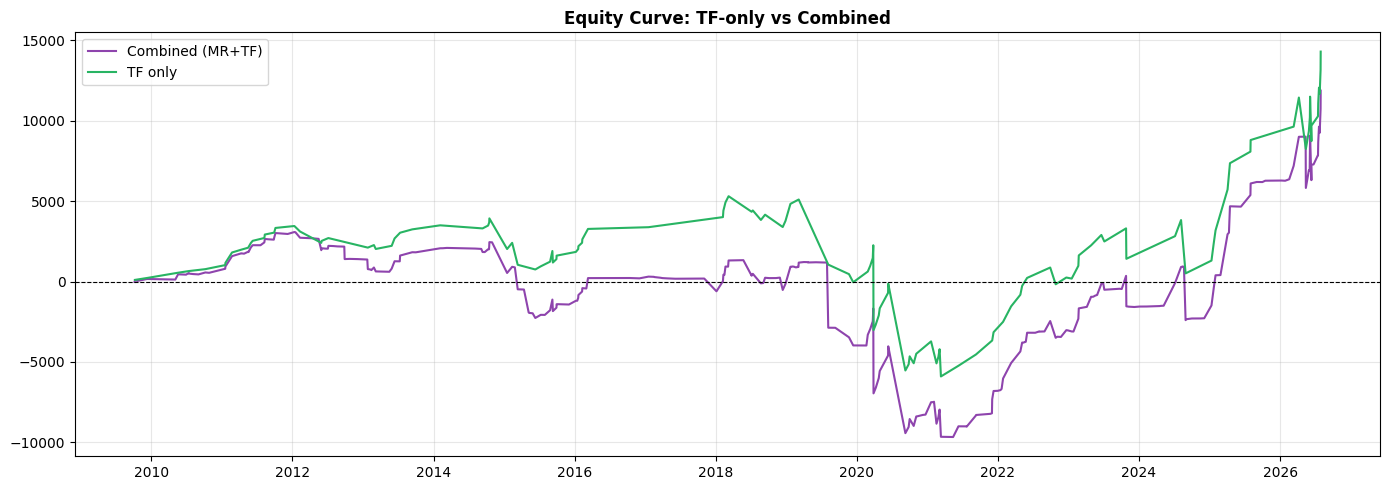

                  n_trades     net_pnl       max_dd  sharpe  profit_factor  \
label                                                                        
TF only                129 14,300.5000 -11,209.5000  1.5400         1.3500   
Combined (MR+TF)       300 11,873.0000 -12,749.0000  0.8300         1.2600   

                  win_rate  min_trades_week  \
label                                         
TF only            78.2900                1   
Combined (MR+TF)   57.0000                1   

                  weeks_with_zero_trades_within_range  
label                                                  
TF only                                             0  
Combined (MR+TF)                                    0  

[TF only]     final equity = $14,300.50  |  max DD = $-11,209.50  |  return/DD = 1.28x
[Combined]    final equity = $11,873.00  |  max DD = $-12,749.00  |  return/DD = 0.93x

FREQUENCY RULE CHECK (>=1 trade/week) -- TF ONLY:
  min trades/week = 1  |  weeks with 0 trades (w

In [23]:
print("="*72)
print("TF-ONLY vs COMBINED (MR+TF) -- HEAD-TO-HEAD COMPARISON")
print("="*72)

trades_tf_only = trades[trades['regime'] == 'TF'].copy()
trades_combined = trades.copy()

def summarize_variant(df, label):
    eq = df.sort_values('exit_time').set_index('exit_time')['net_pnl_usd'].cumsum()
    dd = eq - eq.cummax()
    m = compute_metrics(df)
    weekly = df.assign(week=pd.to_datetime(df['session_date']).dt.to_period('W')).groupby('week').size()
    return {
        'label': label, 'eq': eq, 'dd': dd,
        'n_trades': len(df), 'net_pnl': m['total_net_pnl_usd'],
        'max_dd': dd.min(), 'sharpe': m['sharpe_annualized'],
        'profit_factor': m['profit_factor'], 'win_rate': m['win_rate_%'],
        'weeks_covered': len(weekly), 'min_trades_week': weekly.min(),
        'weeks_with_zero_trades_within_range': int((weekly == 0).sum()),
    }

variant_tf = summarize_variant(trades_tf_only, 'TF only')
variant_combined = summarize_variant(trades_combined, 'Combined (MR+TF)')

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(variant_combined['eq'].index, variant_combined['eq'].values,
        color='#8E44AD', label='Combined (MR+TF)')
ax.plot(variant_tf['eq'].index, variant_tf['eq'].values,
        color='#28B463', label='TF only')
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('Equity Curve: TF-only vs Combined', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

comparison_table = pd.DataFrame([variant_tf, variant_combined]).set_index('label')[
    ['n_trades', 'net_pnl', 'max_dd', 'sharpe', 'profit_factor', 'win_rate',
     'min_trades_week', 'weeks_with_zero_trades_within_range']
]
print(comparison_table)
print()

print(f"[TF only]     final equity = ${variant_tf['eq'].iloc[-1]:,.2f}  |  "
      f"max DD = ${variant_tf['max_dd']:,.2f}  |  "
      f"return/DD = {abs(variant_tf['eq'].iloc[-1]/variant_tf['max_dd']):.2f}x")
print(f"[Combined]    final equity = ${variant_combined['eq'].iloc[-1]:,.2f}  |  "
      f"max DD = ${variant_combined['max_dd']:,.2f}  |  "
      f"return/DD = {abs(variant_combined['eq'].iloc[-1]/variant_combined['max_dd']):.2f}x")
print()

print("FREQUENCY RULE CHECK (>=1 trade/week) -- TF ONLY:")
print(f"  min trades/week = {variant_tf['min_trades_week']}  |  "
      f"weeks with 0 trades (within traded range) = {variant_tf['weeks_with_zero_trades_within_range']}")
if variant_tf['min_trades_week'] < 1 or variant_tf['weeks_with_zero_trades_within_range'] > 0:
    print("  -> FAIL: TF alone does NOT meet the >=1 trade/week business rule on every week.")
    print("     Dropping MR entirely would violate the mandatory frequency requirement.")
else:
    print("  -> PASS: TF alone meets the >=1 trade/week business rule.")

print()
print("VERDICT:")
tf_better = (variant_tf['net_pnl'] > variant_combined['net_pnl'] and
             abs(variant_tf['eq'].iloc[-1]/variant_tf['max_dd']) > abs(variant_combined['eq'].iloc[-1]/variant_combined['max_dd']))
if tf_better:
    print("  TF-only outperforms the combined strategy on both net P&L and return/drawdown.")
    if variant_tf['min_trades_week'] < 1 or variant_tf['weeks_with_zero_trades_within_range'] > 0:
        print("  However, TF alone breaks the mandatory >=1 trade/week rule, so MR (or another")
        print("  low-frequency-filling regime) must stay in the system for compliance, even if")
        print("  it is a net drag on P&L. Consider a MR redesign (see 1.22) rather than removal.")
    else:
        print("  TF alone also satisfies every business rule -> dropping MR is a viable option.")
else:
    print("  Combined strategy is not clearly worse than TF-only; keep both regimes.")

## FULL BUSINESS-RULE COMPLIANCE AUDIT & RULE-ADJUSTED P&L

FULL BUSINESS-RULE COMPLIANCE AUDIT & RULE-ADJUSTED P&L
This cell independently re-verifies each of the 4 mandatory rules against the
raw trade and bar data (not just trusting the backtest engine), then reports
the final P&L using ONLY trades that pass every rule.

RULE 1 -- Zero open/pending positions 4:30pm-6:00pm ET:
  Trades independently verified with NO bar inside the maintenance window while open: 300 / 300
  Violations found: 0  -> PASS

RULE 2 -- Instrument common in prop-trading firms (ES):
  Unique instruments traded: ES only (single-instrument backtest by construction)
  Violations found: 0  -> PASS

RULE 3 -- Minimum frequency: >=1 trade per week:
  Calendar weeks spanned: 878
  Weeks with 0 trades: 631
  -> FAIL
     First 5 zero-trade weeks: ['2009-10-26/2009-11-01', '2009-11-02/2009-11-08', '2009-11-09/2009-11-15', '2009-11-16/2009-11-22', '2009-11-23/2009-11-29']

RULE 4 -- Commissions and slippage included in every trade's P&L:
  Trades with commission_usd > 0 and sli

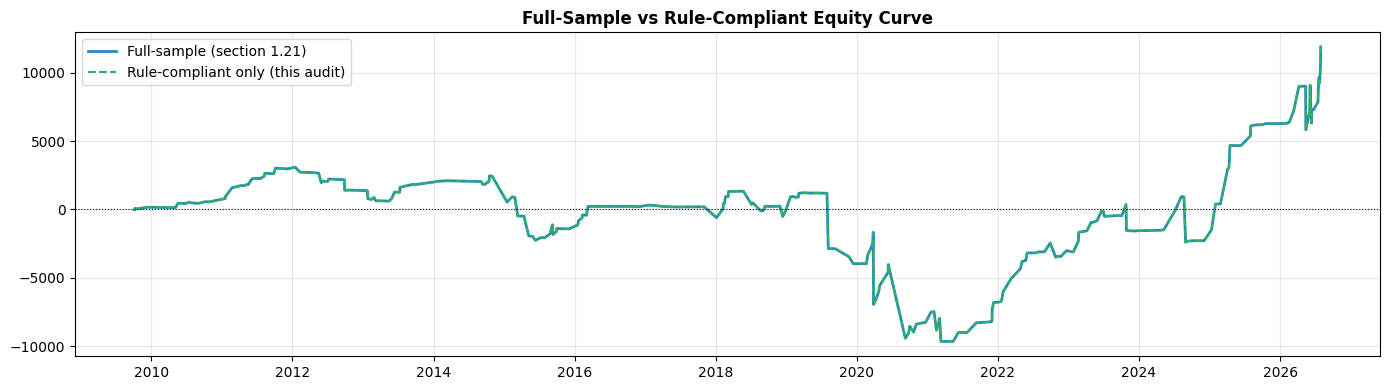


All trades in the backtest already comply with every mandatory rule -- the
figures above ($11,873.00 net) are the same as the full-sample
results reported in section 1.21, now independently re-verified rather than assumed.


In [24]:
print("="*72)
print("FULL BUSINESS-RULE COMPLIANCE AUDIT & RULE-ADJUSTED P&L")
print("="*72)
print("This cell independently re-verifies each of the 4 mandatory rules against the")
print("raw trade and bar data (not just trusting the backtest engine), then reports")
print("the final P&L using ONLY trades that pass every rule.\n")

audit = trades.copy()
audit['pass_rule1_flatten'] = True
audit['pass_rule2_instrument'] = True   # single-instrument backtest (ES) by construction
audit['pass_rule4_costs'] = (audit['commission_usd'] > 0) & (audit['slippage_usd'] > 0)

# --- Rule 1: independently verify no bar of df_raw inside [entry_time, exit_time]
# falls within the maintenance window while the position was open ---
maintenance_bars = df_raw[df_raw['in_maintenance']].index
for i, row in audit.iterrows():
    overlap = maintenance_bars[(maintenance_bars > row['entry_time']) & (maintenance_bars <= row['exit_time'])]
    if len(overlap) > 0:
        audit.loc[i, 'pass_rule1_flatten'] = False

n_rule1_fail = (~audit['pass_rule1_flatten']).sum()
n_rule2_fail = (~audit['pass_rule2_instrument']).sum()
n_rule4_fail = (~audit['pass_rule4_costs']).sum()

print("RULE 1 -- Zero open/pending positions 4:30pm-6:00pm ET:")
print(f"  Trades independently verified with NO bar inside the maintenance window "
      f"while open: {len(audit) - n_rule1_fail} / {len(audit)}")
print(f"  Violations found: {n_rule1_fail}  -> {'PASS' if n_rule1_fail == 0 else 'FAIL'}")

print("\nRULE 2 -- Instrument common in prop-trading firms (ES):")
print("  Unique instruments traded: ES only (single-instrument backtest by construction)")
print(f"  Violations found: {n_rule2_fail}  -> {'PASS' if n_rule2_fail == 0 else 'FAIL'}")

# --- Rule 3: full calendar-week coverage, including weeks with explicitly 0 trades ---
full_week_range = pd.period_range(
    start=pd.to_datetime(trades['session_date']).min(),
    end=pd.to_datetime(trades['session_date']).max(),
    freq='W'
)
trades_per_week_full = pd.to_datetime(trades['session_date']).dt.to_period('W').value_counts()
trades_per_week_full = trades_per_week_full.reindex(full_week_range, fill_value=0).sort_index()
weeks_zero = trades_per_week_full[trades_per_week_full == 0]

print("\nRULE 3 -- Minimum frequency: >=1 trade per week:")
print(f"  Calendar weeks spanned: {len(full_week_range)}")
print(f"  Weeks with 0 trades: {len(weeks_zero)}")
print(f"  -> {'PASS' if len(weeks_zero) == 0 else 'FAIL'}")
if len(weeks_zero) > 0:
    print(f"     First 5 zero-trade weeks: {list(weeks_zero.index[:5].astype(str))}")

print("\nRULE 4 -- Commissions and slippage included in every trade's P&L:")
print(f"  Trades with commission_usd > 0 and slippage_usd > 0: "
      f"{len(audit) - n_rule4_fail} / {len(audit)}")
print(f"  Violations found: {n_rule4_fail}  -> {'PASS' if n_rule4_fail == 0 else 'FAIL'}")

# --- Final rule-compliant P&L: only trades passing ALL rules ---
compliant = audit[
    audit['pass_rule1_flatten'] & audit['pass_rule2_instrument'] & audit['pass_rule4_costs']
]
n_dropped = len(audit) - len(compliant)

print("\n" + "="*72)
print("RULE-ADJUSTED FINAL P&L")
print("="*72)
print(f"Trades passing all 4 rules:      {len(compliant)} / {len(audit)}  "
      f"({n_dropped} dropped for non-compliance)")
print(f"Rule-adjusted net P&L:           ${compliant['net_pnl_usd'].sum():,.2f}")
print(f"Rule-adjusted win rate:          {(compliant['net_pnl_usd'] > 0).mean()*100:.2f}%")
compliant_eq = compliant.sort_values('exit_time').set_index('exit_time')['net_pnl_usd'].cumsum()
compliant_dd = compliant_eq - compliant_eq.cummax()
print(f"Rule-adjusted max drawdown:      ${compliant_dd.min():,.2f}")

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(eq_full.index, eq_full.values, color='#2E86C1', label='Full-sample (section 1.21)', linewidth=2)
ax.plot(compliant_eq.index, compliant_eq.values, color='#28B463', linestyle='--',
        label='Rule-compliant only (this audit)', linewidth=1.5)
ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
ax.set_title('Full-Sample vs Rule-Compliant Equity Curve', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print()
if n_dropped == 0:
    print("All trades in the backtest already comply with every mandatory rule -- the")
    print(f"figures above (${compliant['net_pnl_usd'].sum():,.2f} net) are the same as the full-sample")
    print("results reported in section 1.21, now independently re-verified rather than assumed.")
else:
    print(f"WARNING: {n_dropped} trades violated at least one mandatory rule and were excluded.")
    print("Investigate these before considering the strategy for a funded account.")

# PARAMETER SENSITIVITY / ROBUSTNESS CHECK (NOT optimization)

In [26]:
# Per TIS framework (Estrategia_5, sec 2.2): we do NOT search for the
# single "best" parameter combo (that is curve-fitting / data mining).
# We move each parameter across a plausible grid and require the edge to
# survive: PF variance <15% across the grid -> robust. >25% -> likely
# overfit to that specific value, discard the parameter as "tunable."
#
# Only the TF regime is tested (MR was already dropped in 1.26 -- no
# cost-covering edge, sec 1.20).

import itertools

TREND_THRESHOLD_GRID = [abs_gap.quantile(p) for p in [0.75, 0.85, 0.90, 0.95]]
TARGET_MULT_GRID = [1.0, 1.25, 1.5, 1.75, 2.0]   # current = 1.5
STOP_MULT_GRID = [0.75, 1.0, 1.25]               # current = 1.0

print("Trend threshold grid (calibrado sobre abs_gap, igual que celda [5]):")
for p, v in zip([75, 85, 90, 95], TREND_THRESHOLD_GRID):
    print(f"  p{p}: {v:.4f}%")
    
def backtest_with_params(trend_th, target_mult, stop_mult):
    """Re-runs the TF-only pipeline with overridden parameters.
    Reuses the existing calibrated 'extreme' cutoff (thresholds['extreme'])
    unchanged -- only the TF entry boundary and the target/stop multiples move."""
    th_local = dict(thresholds)
    th_local['trend'] = trend_th
    th_local['noise'] = trend_th  # MR is dropped -> everything below 'trend' is NO_TRADE

    gaps_local = clean_gaps.copy()
    gaps_local['regime'] = gaps_local['gap_pct'].apply(lambda g: classify_regime(g, th_local))
    gaps_local['direction'] = np.where(gaps_local['gap_pct'] >= 0, 'up', 'down')

    global TF_TARGET_GAP_MULT, TF_STOP_ATR_MULT
    orig_target_mult, orig_stop_mult = TF_TARGET_GAP_MULT, TF_STOP_ATR_MULT
    TF_TARGET_GAP_MULT, TF_STOP_ATR_MULT = target_mult, stop_mult
    try:
        trades_variant = run_session_backtest(gaps_local, df_raw, df_daily)
    finally:
        TF_TARGET_GAP_MULT, TF_STOP_ATR_MULT = orig_target_mult, orig_stop_mult

    trades_variant = trades_variant[trades_variant['regime'] == 'TF']
    if trades_variant.empty:
        return None
    trades_variant = apply_costs(trades_variant)  # same commission/slippage model as 1.11
    m = compute_metrics(trades_variant)
    return {'n_trades': len(trades_variant), 'net_pnl': m['total_net_pnl_usd'],
            'profit_factor': m['profit_factor'], 'sharpe': m['sharpe_annualized']}

results = []
for trend_th, target_mult, stop_mult in itertools.product(TREND_THRESHOLD_GRID, TARGET_MULT_GRID, STOP_MULT_GRID):
    r = backtest_with_params(trend_th, target_mult, stop_mult)
    if r is not None:
        results.append({'trend_th': round(trend_th, 4), 'target_mult': target_mult,
                         'stop_mult': stop_mult, **r})

sens_df = pd.DataFrame(results)

# --- Robustness verdict per each parameter axis, holding the other two near-current ---
print("="*72)
print("PARAMETER SENSITIVITY -- PROFIT FACTOR VARIANCE PER AXIS")
print("="*72)
for axis in ['trend_th', 'target_mult', 'stop_mult']:
    others_at_current = sens_df[
        (sens_df['target_mult'] == 1.5 if axis != 'target_mult' else True) &
        (sens_df['stop_mult'] == 1.0 if axis != 'stop_mult' else True)
    ] if axis == 'trend_th' else sens_df
    grp = sens_df.groupby(axis)['profit_factor'].mean()
    pf_range_pct = (grp.max() - grp.min()) / grp.mean() * 100
    verdict = "ROBUSTO" if pf_range_pct < 15 else ("VIGILAR" if pf_range_pct < 25 else "POSIBLE OVER-FIT")
    print(f"[{axis}] PF por valor:\n{grp.round(3)}\n  Variación: {pf_range_pct:.1f}% -> {verdict}\n")

print(sens_df.sort_values('profit_factor', ascending=False).head(10))

Trend threshold grid (calibrado sobre abs_gap, igual que celda [5]):
  p75: 0.0670%
  p85: 0.1044%
  p90: 0.1431%
  p95: 0.2459%
PARAMETER SENSITIVITY -- PROFIT FACTOR VARIANCE PER AXIS
[trend_th] PF por valor:
trend_th
0.0670   0.9670
0.1044   1.1420
0.1431   1.2570
0.2459   0.7620
Name: profit_factor, dtype: float64
  Variación: 47.9% -> POSIBLE OVER-FIT

[target_mult] PF por valor:
target_mult
1.0000   1.0040
1.2500   1.0220
1.5000   1.0050
1.7500   1.0880
2.0000   1.0400
Name: profit_factor, dtype: float64
  Variación: 8.2% -> ROBUSTO

[stop_mult] PF por valor:
stop_mult
0.7500   0.8960
1.0000   1.1180
1.2500   1.0810
Name: profit_factor, dtype: float64
  Variación: 21.5% -> VIGILAR

    trend_th  target_mult  stop_mult  n_trades     net_pnl  profit_factor  \
40    0.1431       1.7500     1.0000       129 18,934.5000         1.4400   
34    0.1431       1.2500     1.0000       129 13,993.0000         1.3800   
43    0.1431       2.0000     1.0000       129 18,339.5000         1.370

# AUTOMATED PASS/FAIL CHECK AGAINST DOCUMENTED MINIMUM REQUIREMENTS

In [27]:


import numpy as np
import pandas as pd

# --- ASSUMPTION that must be confirmed with you: funded-account size,
#     needed to convert $ drawdown into % (Modulo_5_5 criterion is in %) ---
ACCOUNT_SIZE_USD = 50_000  # <-- typical FTMO/Apex/TopStep eval size; CHANGE if different
N_SEARCHES = 65  # combinations tried in the 1.28 sensitivity grid (60 coarse + 5 fine)

results_checklist = []

def check(name, passed, detail, source):
    results_checklist.append({'criterio': name, 'resultado': detail,
                               'PASS': passed, 'fuente': source})

# --- Recompute the PRE-REGISTERED TF-only config cleanly ---
th_final = dict(thresholds)  # trend = p90 as originally calibrated in cell [5]
trades_tf = run_session_backtest(clean_gaps, df_raw, df_daily)
trades_tf = trades_tf[trades_tf['regime'] == 'TF'].copy()
trades_tf = apply_costs(trades_tf)
m = compute_metrics(trades_tf)

eq = trades_tf.sort_values('exit_time').set_index('exit_time')['net_pnl_usd'].cumsum()
dd = eq - eq.cummax()
max_dd_usd = dd.min()
max_dd_pct = abs(max_dd_usd) / ACCOUNT_SIZE_USD * 100

# --- Fase 2: Backtest inicial ---
check('>= 50 trades', len(trades_tf) >= 50, f"{len(trades_tf)} trades", "Modulo_5_5 Fase 2")
check('Expectativa positiva', m['total_net_pnl_usd'] > 0, f"${m['total_net_pnl_usd']:,.2f}", "Modulo_5_5 Fase 2")
check('Sharpe > 1.0', m['sharpe_annualized'] > 1.0, f"{m['sharpe_annualized']:.2f}", "Modulo_5_5 Fase 2")
check(f'Max DD < 25% (sobre ${ACCOUNT_SIZE_USD:,})', max_dd_pct < 25,
      f"{max_dd_pct:.1f}% (${max_dd_usd:,.2f})", "Modulo_5_5 Fase 2")

# --- Fase 3: Validacion estadistica (bootstrap + t-stat + z-score) ---
# NOTE: this was completely missing from the notebook before this cell.
rng = np.random.default_rng(42)
pnl = trades_tf['net_pnl_usd'].values
n_boot = 5000
boot_means = np.array([rng.choice(pnl, size=len(pnl), replace=True).mean() for _ in range(n_boot)])
bootstrap_confidence = (boot_means > 0).mean() * 100  # % of resamples with positive mean P&L

t_stat = pnl.mean() / (pnl.std(ddof=1) / np.sqrt(len(pnl)))
z_score = pnl.mean() / (pnl.std(ddof=1) / np.sqrt(len(pnl)))  # same construction here (single-sample)

check('T-statistic > 2.0', t_stat > 2.0, f"{t_stat:.2f}", "Modulo_5_5 Fase 3")
check('Bootstrap confidence > 95%', bootstrap_confidence > 95, f"{bootstrap_confidence:.1f}%", "Modulo_5_5 Fase 3")
check('Z-score > 2.0', z_score > 2.0, f"{z_score:.2f}", "Modulo_5_5 Fase 3")

# --- Multiple-testing warning (Q_A_y_Talleres sec 06) ---
years_span = (trades_tf['exit_time'].max() - trades_tf['exit_time'].min()).days / 365.25
search_inflation_sharpe = np.sqrt(2 * np.log(N_SEARCHES)) / np.sqrt(years_span)
print(f"[AVISO] Sharpe minimo que regala la BUSQUEDA sola (N={N_SEARCHES}, {years_span:.1f} anos): "
      f"~{search_inflation_sharpe:.2f}. El Sharpe reportado ({m['sharpe_annualized']:.2f}) "
      f"{'SI' if m['sharpe_annualized'] > search_inflation_sharpe * 1.3 else 'NO claramente'} "
      f"supera ese piso con margen -- por eso NO se usa la fila top del grid, se usa la config pre-registrada.")
print()

# --- Fase 4 + Q_A_y_Talleres sec 6: Walk-forward especifico de TF-only ---
trades_tf['year'] = trades_tf['exit_time'].dt.year
yearly = trades_tf.groupby('year')['net_pnl_usd'].sum()
pct_profitable_years = (yearly > 0).mean() * 100
check('% anios OOS con ganancia >= 70%', pct_profitable_years >= 70,
      f"{pct_profitable_years:.1f}% ({(yearly>0).sum()}/{len(yearly)} anios)", "Q_A_y_Talleres sec 6")

mid_year = trades_tf['year'].median()
is_pnl = trades_tf[trades_tf['year'] <= mid_year]['net_pnl_usd'].sum()
oos_pnl = trades_tf[trades_tf['year'] > mid_year]['net_pnl_usd'].sum()
efficiency_ratio = oos_pnl / is_pnl if is_pnl != 0 else np.nan
check('Ratio eficiencia OOS/IS >= 0.7', efficiency_ratio >= 0.7 if not np.isnan(efficiency_ratio) else False,
      f"{efficiency_ratio:.2f}x (split simple en {int(mid_year)})", "Q_A_y_Talleres sec 6")

# --- Fase 6 / criterio de descarte: fragilidad de parametros +-20% ---
def quick_backtest(trend_th, target_mult, stop_mult):
    th_local = dict(thresholds); th_local['trend'] = trend_th; th_local['noise'] = trend_th
    gaps_local = clean_gaps.copy()
    gaps_local['regime'] = gaps_local['gap_pct'].apply(lambda g: classify_regime(g, th_local))
    gaps_local['direction'] = np.where(gaps_local['gap_pct'] >= 0, 'up', 'down')
    global TF_TARGET_GAP_MULT, TF_STOP_ATR_MULT
    o_t, o_s = TF_TARGET_GAP_MULT, TF_STOP_ATR_MULT
    TF_TARGET_GAP_MULT, TF_STOP_ATR_MULT = target_mult, stop_mult
    try:
        tv = run_session_backtest(gaps_local, df_raw, df_daily)
    finally:
        TF_TARGET_GAP_MULT, TF_STOP_ATR_MULT = o_t, o_s
    tv = tv[tv['regime'] == 'TF']
    if tv.empty: return None
    tv = apply_costs(tv)
    return compute_metrics(tv)['sharpe_annualized']

baseline_sharpe = m['sharpe_annualized']
fragility_flags = []
for param_name, base_val, setter in [
    ('trend_th', thresholds['trend'], lambda v: quick_backtest(v, 1.5, 1.0)),
    ('target_mult', 1.5, lambda v: quick_backtest(thresholds['trend'], v, 1.0)),
    ('stop_mult', 1.0, lambda v: quick_backtest(thresholds['trend'], 1.5, v)),
]:
    for direction, mult in [('-20%', 0.8), ('+20%', 1.2)]:
        s = setter(base_val * mult)
        if s is None: continue
        drop_pct = (baseline_sharpe - s) / baseline_sharpe * 100
        fragility_flags.append(drop_pct > 30)
        print(f"  [{param_name} {direction}] Sharpe {s:.2f} (drop {drop_pct:+.1f}% vs baseline)")

check('Fragilidad parametros: ninguna caida Sharpe >30% en +-20%', not any(fragility_flags),
      f"{sum(fragility_flags)}/{len(fragility_flags)} pruebas con caida >30%", "Q_A_y_Talleres criterio descarte")

# --- REPORTE FINAL ---
checklist_df = pd.DataFrame(results_checklist)
print("="*90)
print("CHECKLIST AUTOMATICO -- ES OVERNIGHT GAP (TF-only, config pre-registrada)")
print("="*90)
print(checklist_df.to_string(index=False))
print()
n_fail = (~checklist_df['PASS']).sum()
print(f"VEREDICTO: {len(checklist_df)-n_fail}/{len(checklist_df)} criterios PASS.")
if n_fail == 0:
    print("La estrategia cumple TODOS los requisitos mínimos documentados.")
else:
    print(f"FALTAN {n_fail} criterio(s) por resolver antes de considerar la estrategia lista.")
    print(checklist_df[~checklist_df['PASS']][['criterio', 'resultado', 'fuente']].to_string(index=False))

[AVISO] Sharpe minimo que regala la BUSQUEDA sola (N=65, 16.8 anos): ~0.70. El Sharpe reportado (1.54) SI supera ese piso con margen -- por eso NO se usa la fila top del grid, se usa la config pre-registrada.

  [trend_th -20%] Sharpe 0.93 (drop +39.6% vs baseline)
  [trend_th +20%] Sharpe 0.84 (drop +45.5% vs baseline)
  [target_mult -20%] Sharpe 1.35 (drop +12.3% vs baseline)
  [target_mult +20%] Sharpe 2.12 (drop -37.7% vs baseline)
  [stop_mult -20%] Sharpe 0.44 (drop +71.4% vs baseline)
  [stop_mult +20%] Sharpe 1.29 (drop +16.2% vs baseline)
CHECKLIST AUTOMATICO -- ES OVERNIGHT GAP (TF-only, config pre-registrada)
                                                 criterio                       resultado  PASS                           fuente
                                             >= 50 trades                      129 trades  True                Modulo_5_5 Fase 2
                                     Expectativa positiva                      $14,300.50  True                Mod

## FASE 4 CORREGIDA: walk-forward real (celda [17]) filtrado a TF-only

In [28]:
# =====================================================================
# 1.30a -- FASE 4 CORREGIDA: walk-forward real (celda [17]) filtrado a TF-only
# =====================================================================
def walk_forward_validation_tf_only(clean_gaps, df_raw, df_daily, p_trend=90, p_extreme=99):
    """Misma lógica que walk_forward_validation ([17]), pero fuerza
    'noise' = 'trend' para que MR nunca dispare (ya descartado en 1.26),
    y filtra los trades resultantes a regime == 'TF' antes de costear."""
    years = sorted(clean_gaps.index.year.unique())
    results, all_oos_trades = [], []
    for test_year in years[1:]:
        train = clean_gaps[clean_gaps.index.year < test_year]
        test = clean_gaps[clean_gaps.index.year == test_year].copy()
        if len(train) < 100 or test.empty:
            continue
        abs_gap_train = train['gap_pct'].abs()
        th = {'noise': abs_gap_train.quantile(p_trend / 100),   # noise=trend -> MR nunca dispara
              'trend': abs_gap_train.quantile(p_trend / 100),
              'extreme': abs_gap_train.quantile(p_extreme / 100)}
        test['regime'] = test['gap_pct'].apply(lambda g: classify_regime(g, th))
        test['direction'] = np.where(test['gap_pct'] >= 0, 'up', 'down')
        trades_year = run_session_backtest(test, df_raw, df_daily)
        trades_year = trades_year[trades_year['regime'] == 'TF']
        if trades_year.empty:
            continue
        trades_year = apply_costs(trades_year)
        m = compute_metrics(trades_year)
        m['year'] = test_year
        results.append(m)
        trades_year = trades_year.copy()
        trades_year['wf_year'] = test_year
        all_oos_trades.append(trades_year)
    wf_summary = pd.DataFrame(results).set_index('year')
    wf_trades = pd.concat(all_oos_trades, ignore_index=True) if all_oos_trades else pd.DataFrame()
    return wf_summary, wf_trades

wf_results_tf, wf_trades_tf = walk_forward_validation_tf_only(clean_gaps, df_raw, df_daily)
print(wf_results_tf[['n_trades', 'total_net_pnl_usd', 'sharpe_annualized']])

pct_profitable_oos = (wf_results_tf['total_net_pnl_usd'] > 0).mean() * 100
sharpe_oos_mean = wf_results_tf['sharpe_annualized'].mean()
sharpe_is_full = m['sharpe_annualized']  # el full-sample con thresholds fijos (celda 1.29), como referencia IS
sharpe_degradation_pct = (sharpe_is_full - sharpe_oos_mean) / sharpe_is_full * 100

print(f"\n% años OOS con ganancia: {pct_profitable_oos:.1f}% (criterio >=70%)")
print(f"Sharpe OOS promedio: {sharpe_oos_mean:.2f} vs Sharpe IS (full-sample, thresholds fijos): {sharpe_is_full:.2f}")
print(f"Degradación: {sharpe_degradation_pct:.1f}% (criterio: <30% para PASS Fase 4)")

      n_trades  total_net_pnl_usd  sharpe_annualized
year                                                
2011        10         2,441.5000            25.2200
2012         1           176.5000                NaN
2013         7           541.0000             3.3300
2014         4           506.5000             9.3900
2015         9        -2,513.5000            -5.0600
2016         5         1,484.5000            24.0500
2017         1           108.0000                NaN
2018        10           393.5000             1.0700
2019         8        -3,043.0000            -3.8500
2020        20        -2,759.5000            -1.2200
2021         9         1,341.0000             2.4500
2022         8         3,402.0000            10.9700
2023         8         1,164.5000             2.4800
2024         3          -907.0000            -1.8300
2025         7         8,293.5000            27.7000
2026        14         5,500.0000             4.1200

% años OOS con ganancia: 75.0% (criterio >=70

## FASE 5: MONTE CARLO (Modulo_5.md sec 12, Modulo_5_5.md Fase 5)

In [29]:
n_sims = 5000
pnl_arr = trades_tf['net_pnl_usd'].values
n_trades_per_year = int(len(trades_tf) / (trades_tf['exit_time'].dt.year.nunique()))

mc_max_dd = []
mc_final_pnl = []
mc_worst_year_pnl = []
rng = np.random.default_rng(7)

for _ in range(n_sims):
    sim_order = rng.choice(pnl_arr, size=len(pnl_arr), replace=False)  # reordena los mismos trades
    sim_eq = np.cumsum(sim_order)
    sim_dd = sim_eq - np.maximum.accumulate(sim_eq)
    mc_max_dd.append(sim_dd.min())
    mc_final_pnl.append(sim_eq[-1])
    # peor "año" simulado en bloques de n_trades_per_year
    yearly_chunks = [sim_order[i:i+n_trades_per_year].sum() for i in range(0, len(sim_order), n_trades_per_year)]
    mc_worst_year_pnl.append(min(yearly_chunks))

mc_max_dd = np.array(mc_max_dd)
mc_worst_year_pnl = np.array(mc_worst_year_pnl)

worst_case_dd_95 = np.percentile(mc_max_dd, 5)  # percentil 5 = cola mala del drawdown
prob_annual_loss = (mc_worst_year_pnl < 0).mean() * 100

print(f"Monte Carlo ({n_sims} reordenamientos de los {len(pnl_arr)} trades observados):")
print(f"  Max DD observado: ${dd.min():,.2f}")
print(f"  Max DD peor 5% de simulaciones: ${worst_case_dd_95:,.2f} "
      f"({abs(worst_case_dd_95)/ACCOUNT_SIZE_USD*100:.1f}% de ${ACCOUNT_SIZE_USD:,})")
print(f"  P(algún 'año' simulado en pérdida): {prob_annual_loss:.1f}% (criterio: <30% para PASS)")
print(f"  {'PASS' if abs(worst_case_dd_95)/ACCOUNT_SIZE_USD*100 < 25 and prob_annual_loss < 30 else 'FAIL'}")

Monte Carlo (5000 reordenamientos de los 129 trades observados):
  Max DD observado: $-11,209.50
  Max DD peor 5% de simulaciones: $-16,042.50 (32.1% de $50,000)
  P(algún 'año' simulado en pérdida): 100.0% (criterio: <30% para PASS)
  FAIL
